# Waar kunnen biogene riffen op de Noordzee worden hersteld?

*Analyse met BeaconIHM en aanvullende open bronnen (EMODnet, Marine Regions)*

# 1. Overzicht en doelstelling

## De vraag

Waar op het Nederlandse deel van de Noordzee kunnen **biogene riffen** worden hersteld? Biogene riffen zijn harde, driedimensionale structuren die dieren zelf bouwen. Voorbeelden zijn banken van de **platte oester** (*Ostrea edulis*), riffen van de **driedoornige zandkokerworm** (*Sabellaria spinulosa*) en banken van de **paardenmossel** (*Modiolus modiolus*).

De vraag bestaat uit drie delen:

- **a.** Welke gebieden zijn potentieel geschikt? Daarbij tellen bodemtype en diepte, huidige aanwezigheid of historische geschiktheid, beschermde gebieden en menselijk gebruik.
- **b.** Welke IHM-data kunnen daarvoor worden gebruikt? Het gaat om benthos (MWTL), schelpdierdata en habitat- en zeebodeminformatie, gecombineerd met ruimtelijke informatie over beschermde gebieden en gebruiksfuncties.
- **c.** Een gebied met weinig natuurwaarde is niet automatisch een goede plek voor herstel. Eerst moet duidelijk zijn *waarom* de natuurwaarde laag is, of de randvoorwaarden voor herstel aanwezig zijn en of de soort daar van oorsprong thuishoort. Zo kan **herstel** worden onderscheiden van het **maken van nieuw habitat**.

## Wat doet dit notebook?

Het notebook legt vier soorten informatie over elkaar op een raster van 0,05 graden (ongeveer 3,5 bij 5,5 kilometer):

1. **Ecologisch potentieel.** Modelkaarten uit het IHM tonen hoe geschikt elke plek is voor drie rifbouwers.
2. **Fysieke randvoorwaarden.** Diepte en bodemtype bepalen of een rif kan groeien.
3. **Huidige en historische aanwezigheid.** Waarnemingen van rifbouwers en bekende rifgebieden tonen waar de soort van oorsprong thuishoort.
4. **Drukfactoren en regimes.** Visserij, scheepvaart, windparken, defensie, zand- en schelpwinning, kabels en leidingen en beschermde gebieden bepalen of herstel past bij het gebruik van de zee.

Daarna deelt het notebook elke rastercel in een categorie in. Het notebook schat ook per cel of een gebied *herstel* of *nieuw habitat* zou zijn, en onderzoekt waarom de natuurwaarde in sommige gebieden laag is.

## Wat kunt u verwachten?

Het notebook levert kaarten, tabellen en een lijst van **zones** met kansrijke gebieden. Bij elke zone staan de diepte, het bodemtype, de drukfactoren, de bescherming en het bewijs voor eerdere aanwezigheid.

## Grenzen van de analyse

- De uitkomst is een **eerste ruimtelijke selectie**. Het is geen besluit en geen vergunningstoets.
- De modelkaarten tonen waar een soort kan leven. Ze tonen niet of herstel lukt.
- De gewichten en grenswaarden zijn **keuzes van de analist**. Het notebook toont hun invloed in sectie 8.
- Het notebook gebruikt waarnemingen van aanwezigheid. Een waarneming bewijst niet dat daar ooit een rif lag.
- Het notebook toont geen oorzaak-gevolgrelaties.

# 2. Databronnen en gebruikte data

## 2.1 Bronnen uit de data lake (BeaconIHM)

Alle IHM-bronnen komen van de Beacon-server van het Informatiehuis Marien (`https://beacon-ihm.maris.nl`). De tabelnamen, kolomnamen en eenheden zijn met de MCP-tools `list_tables`, `describe_table` en `run_sql` gecontroleerd. Het notebook haalt alleen samengevatte gegevens per rastercel op.

| Bron (tabel) | Wat bevat de bron? | Waarom nodig? | Gebruikte velden | Periode |
|---|---|---|---|---|
| `prj_mons55_habitat_prediction` | Modelkans (0-1) dat een soort voorkomt, op een fijn raster. Twee modellen per soort (logistische regressie en random forest). | Ecologisch potentieel voor platte oester, zandkokerworm, paardenmossel en tubeworm (*Lanice conchilega*, alleen voor context). | `species`, `model`, `value`, `longitude`, `latitude` | Modelkaart, geen jaar |
| `prj_mons55_presence` en `prj_mons55_presence_datras` | Waarnemingen van aanwezigheid (1) en afwezigheid (0) van dezelfde soorten. | Huidige en historische aanwezigheid. | `species`, `presabs`, `eventDt`, `longitude`, `latitude` | 1902 tot 2018 (datums ontbreken bij de platte oester) |
| `mon_morphology_bathymetry_ncp_2019` | Dieptemodel van het Nederlands Continentaal Plat (meter ten opzichte van NAP, negatief is onder water). | Diepte als randvoorwaarde (hoofdbron). | `value`, `longitude`, `latitude` | Meting 2019 |
| `prj_nzb_depth` | Diepte per locatie (`dn`) en een niet-gedefinieerde markering `gunstig`. | Controle van de diepte. | `dn`, `longitude`, `latitude` | Geen jaar |
| `mon_chemistry_grain_size_sediment` | MWTL-korrelgrootte van de zeebodem (stations). | Controle van het bodemtype (`%KGF63`: slibfractie kleiner dan 63 µm). | `parametercode`, `waarde`, `longitude`, `latitude` | 1996 tot 2018 |
| `mon_benthos_macroinvertebrates_rws` | MWTL-benthos: welke soorten zijn per monster gevonden. | Huidige natuurwaarde (soortenrijkdom) en aanwezigheid van rifbouwers. | `parameter`, `measurementobject`, `collectiondate`, `jaar`, `longitude`, `latitude` | 1989 tot 2022 |
| `mon_benthos_shellfish_wot` | Schelpdiermonitoring (WOT) met aantallen en lengtes. | Aanwezigheid van platte oester, mossel en Japanse oester. | `parameter_omschrijving`, `grootheid_code`, `numeriekewaarde`, `meetpunt_identificatie`, `monsternemingsdatum`, `longitude`, `latitude` | 1993 tot 2025 |
| `prj_dt_fish_yield_2008_2018` | Visserij-opbrengst per cel van 0,0625 bij 0,03125 graden. De eenheid staat niet in de metadata. | Tweede visserij-indicator naast EMODnet (alleen als controle). | `value`, `longitude`, `latitude` | 2008 tot 2018 |

Het notebook heeft ook andere IHM-tabellen bekeken, maar niet gebruikt. `prj_nc2m_voordelta_use` bevat alleen punten van gebruikslocaties zonder omschrijving. `prj_ed_sediment` ligt in het Eems-Dollardestuarium. `prj_nzb_max_wave_height` bevat polygonen die niet op het raster passen. `mon_morphology_bathymetry_20m` dekt alleen het zuidelijke deel. De IHM-tabellen bevatten geen lagen voor scheepvaart, defensie, windparken of beschermde gebieden. Daarom zijn externe bronnen nodig (sectie 2.2).

## 2.2 Externe data en informatie

Dit notebook gebruikt **externe, openbare bronnen**. De externe data zijn gescheiden van de IHM-data en alleen gebruikt voor de ruimtelijke context (bodemtype, drukfactoren en regimes).

| Bron | Laag | Wat halen we op? | Waarom? |
|---|---|---|---|
| Marine Regions (VLIZ), WFS | `MarineRegions:eez` | Grens van de Nederlandse exclusieve economische zone (EEZ). | Beperkt de analyse tot het Nederlandse deel van de Noordzee. |
| EMODnet Seabed Habitats, WMS | `eusm2025_eunis2019_full` (EUSeaMap 2025) | Modelleerde bodemtypeklassen (zand, grof, gemengd, slib en andere). | Bodemtype is een harde randvoorwaarde voor rifgroei. |
| EMODnet Seabed Habitats, WFS | `biogenic_substrate_poly_2025` | Bekende biogene substraten, onder andere banken van de platte oester (OSPAR) en wormriffen. | Bewijs voor eerdere of huidige riffen. |
| EMODnet Human Activities, WFS | `marineprotectedareas`, `natura2000areas` | Mariene beschermde gebieden en Natura 2000. | Bescherming. |
| EMODnet Human Activities, WFS | `fishingbeamtrawls`, `fishingbottomottertrawls`, `fishingdredges` | Gemiddelde visserij-inspanning (MW-vissersuren) per cel van 0,05 graden, gemiddeld over 2021-2024. Alleen schepen langer dan 12 m met VMS. | Visserijdruk op de zeebodem. |
| EMODnet Human Activities, WCS | `vesseldensity_allavg` | Scheepvaartdichtheid uit AIS (uren per km² per maand), jaargemiddelde 2023. | Scheepvaartdruk. |
| EMODnet Human Activities, WFS | `windfarmspoly`, `militaryareaspoly`, `aggregateareas`, `dredgespoilpoly`, `munitionspoly`, `pipelines`, `rijkscables` | Windparken, militaire gebieden, winning van zand en schelpen, stortlocaties, munitiegebieden, leidingen en kabels. | Menselijk gebruik. |
| EMODnet Human Activities, WFS | `mspzoningpolybyusefunction` | Nederlandse gebruiksfuncties uit het Programma Noordzee (onder andere scheepvaartroutes, visserijbeperkingen, defensie en windenergie). | Gebruiksfuncties en regimes. |

Het notebook voert **geen** gegevens uit rapporten of literatuur over historische oesterbanken in. Historische geschiktheid komt alleen uit de waarnemingen en kaarten in de bronnen hierboven.

## 2.3 Data-extractie en scope

- **Studiegebied:** lengtegraad 2,5 tot 7,3 en breedtegraad 51,0 tot 55,8. De analyse en rangschikking gebruiken alleen cellen waarvan het middelpunt in de Nederlandse EEZ ligt. Andere cellen dienen als context.
- **Raster:** cellen van 0,05 graden. De IHM-server middelt of telt de gegevens per cel. Het notebook haalt dus geen ruwe waarnemingen op, behalve voor de controles.
- **Alle records of een deel?** Alle IHM-records in het studiegebied tellen mee, behalve waar de tekst een filter noemt (bijvoorbeeld diepte tussen 0 en 200 in `prj_nzb_depth`).
- **Beperkte monsterdekking:** de benthosmonsters en schelpdiermonsters liggen op vaste stations. Cellen zonder monsters hebben geen waarneming, wat niet hetzelfde is als afwezigheid.
- **Geen toegangsgegevens in het notebook.** Een token (indien nodig) komt uit de omgevingsvariabele `BEACON_IHM_TOKEN`.

De volgende cel laadt de bibliotheken, maakt verbinding met de IHM-server en bevat de instellingen. Alle gewichten en grenswaarden staan op één plek zodat u ze kunt aanpassen.

In [1]:
import contextlib
import io
import json
import os
import tempfile
import warnings
from concurrent.futures import ThreadPoolExecutor

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import rasterio
import requests
import shapely
from beacon_api import Client
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from PIL import Image
from pyproj import Transformer
from scipy import ndimage
from shapely.geometry import box

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

BEACON_IHM_URL = "https://beacon-ihm.maris.nl"
CACHE = os.path.join("output", "cache_biogene_riffen")
os.makedirs(CACHE, exist_ok=True)

client = Client(
    BEACON_IHM_URL,
    user_agent="biogene-riffen-notebook/1.0",
    jwt_token=os.environ.get("BEACON_IHM_TOKEN"),
)
client.check_status()


def run_sql(query):
    """Voer SQL uit op de IHM-server en geef een DataFrame terug."""
    with tempfile.TemporaryDirectory() as tmp:
        path = os.path.join(tmp, "result.parquet")
        with contextlib.redirect_stdout(io.StringIO()):
            client.sql_query(query).to_parquet(path)
        with open(path, "rb") as f:
            table = pq.read_table(io.BytesIO(f.read()))
    for i, field in enumerate(table.schema):
        if pa.types.is_dictionary(field.type):
            table = table.set_column(i, field.name, table.column(i).cast(pa.string()))
    return table.to_pandas()


# ---- Instellingen (keuzes van de analist) ----
BBOX = dict(lon0=2.5, lon1=7.3, lat0=51.0, lat1=55.8)
BIN = 0.05  # celgrootte in graden
IX0, IY0 = round(BBOX["lon0"] / BIN), round(BBOX["lat0"] / BIN)
NX, NY = round((BBOX["lon1"] - BBOX["lon0"]) / BIN), round((BBOX["lat1"] - BBOX["lat0"]) / BIN)
EXTENT = (BBOX["lon0"], BBOX["lon1"], BBOX["lat0"], BBOX["lat1"])
LON_SQL = f"CAST(FLOOR(longitude / {BIN}) AS BIGINT)"
LAT_SQL = f"CAST(FLOOR(latitude / {BIN}) AS BIGINT)"
BBOX_SQL = f"longitude BETWEEN {BBOX['lon0']} AND {BBOX['lon1']} AND latitude BETWEEN {BBOX['lat0']} AND {BBOX['lat1']}"

DEPTH_RANGE_M = (10, 50)  # diepte waarbinnen herstel haalbaar is
# Geschiktheid van het bodemtype voor een rif van platte oester (0 = ongeschikt, 1 = zeer geschikt).
SUBSTRATE_SCORE = {
    "Rock or other hard substrata": 0.8,
    "Coarse substrate": 1.0,
    "Mixed sediment": 1.0,
    "Sand": 0.5,
    "Muddy sand": 0.25,
    "Sandy mud": 0.1,
    "Mud": 0.0,
    "Fine mud": 0.0,
}
MIN_SUBSTRATE_SCORE = 0.4  # onder deze waarde is de bodem te slecht
MIN_KNOWN_SUBSTRATE = 0.5  # minimaal aandeel van de cel met een bekend bodemtype
SPECIES_WEIGHTS = {"p_ostrea": 0.5, "p_sabellaria": 0.25, "p_modiolus": 0.25}
PRESSURE_WEIGHTS = {"fishing": 0.6, "shipping": 0.4}
PRESSURE_PENALTY = 0.7  # hoeveel de drukfactoren de prioriteitsscore verlagen
HIGH_PRESSURE = 0.5  # drukindex vanaf waar een gebied als zwaar belast geldt
TOP_FRACTION = 0.20  # aandeel van de geschikte cellen dat als kansrijk geldt
BLOCK_SHARE = 0.25  # celaandeel binnen een uitsluitend gebruik
NEGOTIATE_SHARE = 0.10  # celaandeel binnen een gebruik waarover overleg nodig is
PROTECTED_SHARE = 0.5  # celaandeel binnen een beschermd gebied
MIN_ZONE_CELLS = 4
LOW_VALUE_QUANTILE = 0.25
MIN_BENTHOS_SAMPLES = 3
REEF_SPECIES = ["ostrea_edulis", "sabellaria_spinulosa", "modiolus_modiolus"]

HA_WFS = "https://ows.emodnet-humanactivities.eu/wfs"
HA_WCS = "https://ows.emodnet-humanactivities.eu/wcs"
SH_WFS = "https://ows.emodnet-seabedhabitats.eu/geoserver/emodnet_open/wfs"
SH_WMS = "https://ows.emodnet-seabedhabitats.eu/geoserver/emodnet_open/wms"
MR_WFS = "https://geo.vliz.be/geoserver/MarineRegions/wfs"
print(f"Raster: {NX} x {NY} cellen van {BIN} graden")

Connected to: https://beacon-ihm.maris.nl/ server successfully
Beacon Version: 2.0.0
Connected to: https://beacon-ihm.maris.nl/ server successfully
Beacon Version: 2.0.0
Raster: 96 x 96 cellen van 0.05 graden


# 3. Aannames, datakwaliteit en voorbereiding

## 3.1 Aannames

| # | Aanname | Reden | Mogelijk effect op de uitkomst |
|---|---|---|---|
| 1 | Alle gewichten en grenswaarden in de instellingencel zijn keuzes van de analist. Ze komen niet van de gebruiker. | De bronnen geven geen vaste grenzen. | De selectie verandert. Sectie 8 toetst dit. |
| 2 | Herstel van de platte oester is het hoofddoel. Zandkokerworm en paardenmossel tellen mee met lager gewicht (0,25 elk). | De vraag noemt de platte oester als voorbeeld. | Een ander gewicht verschuift de zones. |
| 3 | Diepte van 10 tot 50 m is haalbaar voor herstel. | Ondiepe zones hebben veel golfwerking, diepere zones zijn lastig te beheren. Dit is een werkafspraak, geen bronwaarde. | Ondiepe kustcellen vallen af. |
| 4 | Het bodemtype uit EUSeaMap bepaalt een geschiktheidsscore (zie de instellingencel). Grof en gemengd sediment scoren hoog. Zand scoort middelmatig. Slib scoort laag. | Platte oesters en zandkokerwormen hebben hard of gemengd substraat nodig. Op zand is substraat toevoegen nodig. | Zand telt als *mogelijk*, maar het maakt dan nieuw habitat. |
| 5 | Een cel zonder VMS-visserij of AIS-scheepvaart telt als **geen druk** (waarde 0). | De bronnen tonen alleen cellen met activiteit. Visserij door schepen korter dan 12 m ontbreekt. | De druk in de kustzone is mogelijk te laag. |
| 6 | Waarnemingen van aanwezigheid gelden als bewijs dat de soort daar thuishoort. | Er zijn geen gedateerde rifkaarten. | Een zwerver kan ten onrechte als bewijs tellen. |
| 7 | Een cel hoort bij de Nederlandse EEZ als het celmiddelpunt binnen de EEZ-grens ligt. | Eenvoudige, controleerbare regel. | Cellen op de grens kunnen verkeerd vallen. |
| 8 | De drukfactoren *stortlocaties voor baggerspecie, actieve zandwinning (gebieden kleiner dan 1.000 km²) en munitiegebieden* sluiten herstel uit. *Windparken, defensiegebieden en scheepvaartzones (Programma Noordzee)* vragen overleg over medegebruik. *Kabels, leidingen en het grote vergunningsgebied voor schelpenwinning* zijn alleen informatie. | Herstel in windparken is denkbaar (medegebruik), maar vraagt afspraken. Het schelpenwinningsgebied is erg groot (ongeveer een kwart van de EEZ), terwijl de winning zelf plaatselijk is. | Een andere keuze verandert de categorieën. |
| 9 | De plaatsnaam *Oestergronden* in het Programma Noordzee is een aanwijzing dat daar van oudsher platte oesters voorkwamen. Het notebook haalt geen kaart van de historische banken op. | Er zijn in de bronnen geen gedateerde kaarten van historische oesterbanken. | De aanwijzing is zwak: een naam bewijst geen rif. |

## 3.2 Datakwaliteit

De notebook voert deze controles uit. De uitkomsten staan bij de stap zelf en in sectie 8.

- **Volledigheid:** aantal cellen per laag, aandeel cellen zonder waarde.
- **Unieke cellen:** elke rastercel komt één keer voor na het samenvoegen van de lagen.
- **Datumfouten:** de presence-tabel bevat elders datums na 2025. Het notebook telt ze in het studiegebied en sluit ze uit van het onderscheid historisch of recent.
- **Consistentie van twee bronnen:** diepte uit de NCP-bathymetrie tegenover `prj_nzb_depth`. Bodemtype uit EUSeaMap tegenover de slibfractie uit MWTL. Visserijdruk uit EMODnet tegenover de IHM-laag `prj_dt_fish_yield_2008_2018`.
- **Dekking van de monitoring:** aantal benthosmonsters per cel. Cellen met minder dan 3 monsters krijgen geen oordeel over natuurwaarde.

## 3.3 Gegevensvoorbereiding en bewerkingen

1. **Aggregatie naar een raster.** De IHM-server geeft het gemiddelde of de som per cel van 0,05 graden. Dit maakt lagen met verschillende resolutie vergelijkbaar.
2. **Modellen middelen.** Per soort is de kans het gemiddelde van de twee modellen.
3. **Bodemtype per cel.** Per bodemklasse is het aandeel van de cel berekend uit een kaartafbeelding (WMS) van EUSeaMap. Dit is een benadering van het werkelijke polygoonaandeel (zie sectie 10).
4. **Gebiedslagen.** Het aandeel van elke cel binnen een polygoon (beschermd gebied, windpark, enzovoort) is berekend met de geometrie. Lijnen (kabels en leidingen) tellen als markering.
5. **Drukindex.** Visserij en scheepvaart zijn logaritmisch geschaald en begrensd op het 99e percentiel, zodat enkele extreme cellen het beeld niet bepalen. De index loopt van 0 (geen druk) tot 1 (hoogste druk).
6. **Rangpercentielen.** De modelkans per soort wordt omgezet naar een rang binnen de Nederlandse cellen (0-1). Dit voorkomt dat de soort met de hoogste kansen alles bepaalt.

# 4. Interpolatie, schatting en ontbrekende data

## 4.1 Interpolatie

Het notebook **interpoleert niet**. Het vult geen waarden in tussen waarnemingen.

## 4.2 Andere schatting of imputatie

- De IHM-**modelkaarten** (habitatgeschiktheid) zijn zelf modeluitkomsten. Het zijn geen metingen. Het notebook gebruikt ze zoals geleverd en labelt ze als *modelkans*.
- De visserij- en scheepvaartlagen ontbreken in cellen zonder activiteit. Het notebook zet deze cellen op **0** (aanname 5). Dit is een keuze en geen meting.
- Het IHM-bestand `prj_dt_fish_yield_2008_2018` heeft een ander raster. Het notebook koppelt elke cel aan de DT-cel waarin het celmiddelpunt ligt. Er is geen waarde berekend tussen cellen.
- Het bodemtype is afgeleid uit een kaartafbeelding. Het is dus een benadering.

## 4.3 Ontbrekende waarden

Cellen zonder diepte, zonder bekend bodemtype (meer dan 50% onbekend) of zonder benthosmonsters krijgen **geen** schatting. Ze krijgen een aparte uitkomst (bijvoorbeeld *fysiek ongeschikt of onbekend*) of geen oordeel over natuurwaarde.

> Het notebook voert verder geen interpolatie uit. De analyse gebruikt waargenomen of gemodelleerde waarden uit de beschreven bronnen, met de filters en bewerkingen hierboven.

# 5. Analyseaanpak

De analyse volgt zes stappen. Elke stap staat in sectie 6 met een korte uitleg.

1. **Gegevens ophalen en op één raster zetten** (6.1). Eerst de IHM-lagen, dan de externe lagen.
2. **Fysieke randvoorwaarden** (6.2). Diepte en bodemtype bepalen of een cel *fysiek haalbaar* is.
3. **Ecologisch potentieel en bewijs van aanwezigheid** (6.3). Modelkans per soort en waarnemingen bepalen het potentieel en of het gaat om *herstel* of *nieuw habitat*.
4. **Drukfactoren en regimes** (6.4). Visserij, scheepvaart, gebruiksfuncties en bescherming.
5. **Indeling en zones** (6.5). Elke cel krijgt een categorie. Aaneengesloten kansrijke cellen vormen zones.
6. **Waarom is de natuurwaarde laag?** (6.6). Cellen met weinig benthos krijgen een mogelijke oorzaak, zodat herstel niet wordt verward met een plek die het niet verdient of niet aankan.

**Maten.** Potentieel = gewogen rang van de modelkans × bodemgeschiktheid. De prioriteitsscore = potentieel × (1 − 0,7 × drukindex).

**Interpretatie.** Hoge score betekent: de omstandigheden passen bij een rif en de druk is laag. Het notebook toont geen zekerheid dat een rif groeit.

**Beperking.** De methode is een transparante rangschikking met aannames. Er is geen statistische toets.

# 6. Analyse en resultaten

## 6.1 Gegevens ophalen en op één raster zetten

**Wat gebeurt hier?** De IHM-server telt of middelt alle lagen per cel van 0,05 graden. Het notebook voegt de lagen samen op de celcode (`ix`, `iy`). Het notebook controleert dat de samenvoeging geen dubbele cellen maakt.

**Eerst de modelkaart, diepte en bodemdata uit het IHM.**

In [2]:
species_cols = ",\n".join(
    f"AVG(CASE WHEN CAST(species AS VARCHAR) = '{s}' THEN value END) AS p_{k}"
    for s, k in [
        ("ostrea_edulis", "ostrea"),
        ("sabellaria_spinulosa", "sabellaria"),
        ("modiolus_modiolus", "modiolus"),
        ("lanice_conchilega", "lanice"),
    ]
)
habitat = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy, {species_cols}
    FROM prj_mons55_habitat_prediction
    WHERE {BBOX_SQL}
    GROUP BY 1, 2
    """
)
in_grid = habitat["ix"].between(IX0, IX0 + NX - 1) & habitat["iy"].between(IY0, IY0 + NY - 1)
cells = habitat[in_grid].reset_index(drop=True)
cells["lon"] = (cells["ix"] + 0.5) * BIN
cells["lat"] = (cells["iy"] + 0.5) * BIN
cells["area_km2"] = BIN * 111.32 * np.cos(np.radians(cells["lat"])) * BIN * 110.57
print(f"Modelkaart (habitat): {len(cells)} cellen in het raster")


def merge_layer(base, layer):
    n = len(base)
    out = base.merge(layer, on=["ix", "iy"], how="left")
    assert len(out) == n, "De samenvoeging maakt dubbele cellen"
    return out


depth = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy, -AVG(CAST(value AS DOUBLE)) AS depth_m
    FROM mon_morphology_bathymetry_ncp_2019
    WHERE {BBOX_SQL}
    GROUP BY 1, 2
    """
)
depth_nzb = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy,
           AVG(CAST(dn AS DOUBLE)) AS depth_nzb_m, AVG(CAST(gunstig AS DOUBLE)) AS nzb_gunstig
    FROM prj_nzb_depth
    WHERE {BBOX_SQL} AND dn BETWEEN 0 AND 200
    GROUP BY 1, 2
    """
)
mud = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy, AVG(waarde) AS mud_pct, COUNT(*) AS mud_n
    FROM mon_chemistry_grain_size_sediment
    WHERE parametercode = '%KGF63' AND waarde BETWEEN 0 AND 100 AND {BBOX_SQL}
    GROUP BY 1, 2
    """
)
for layer in (depth, depth_nzb, mud):
    cells = merge_layer(cells, layer)
print(f"Diepte (NCP 2019): {depth.shape[0]} cellen | Diepte (NZB, controle): {depth_nzb.shape[0]} cellen | MWTL-slibfractie: {mud.shape[0]} cellen")

Modelkaart (habitat): 6085 cellen in het raster


Diepte (NCP 2019): 3923 cellen | Diepte (NZB, controle): 4504 cellen | MWTL-slibfractie: 126 cellen


**Daarna de waarnemingen van rifbouwers en de benthosdata uit het IHM.**

- *Aanwezigheid* (MONS55): aantal waarnemingen met de soort aanwezig en het totaal aantal waarnemingen, per soort en cel. Datums na 2025 zijn fout en tellen niet mee als recent. Het notebook telt ze apart.
- *Benthos MWTL*: per monster het aantal taxa. Het notebook middelt dit per cel. Een monster is een combinatie van meetpunt en datum.
- *Schelpdieren WOT*: aanwezigheid van platte oester en mossel.

In [3]:
presence = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy, species,
           SUM(CASE WHEN presabs = 1 THEN 1 ELSE 0 END) AS n_pres, COUNT(*) AS n_obs
    FROM (
        SELECT longitude, latitude, presabs, CAST(species AS VARCHAR) AS species FROM prj_mons55_presence
        UNION ALL
        SELECT longitude, latitude, presabs, CAST(species AS VARCHAR) AS species FROM prj_mons55_presence_datras
    ) t
    WHERE {BBOX_SQL} AND species IN ('ostrea_edulis', 'sabellaria_spinulosa', 'modiolus_modiolus')
    GROUP BY 1, 2, 3
    """
)
pres = presence.pivot_table(index=["ix", "iy"], columns="species", values=["n_pres", "n_obs"], aggfunc="sum")
pres.columns = [f"{a}_{b.split('_')[0]}" for a, b in pres.columns]
pres = pres.reset_index()

dated = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy,
           SUM(CASE WHEN presabs = 1 AND "eventDt" < DATE '1990-01-01' THEN 1 ELSE 0 END) AS pres_before_1990,
           SUM(CASE WHEN presabs = 1 AND "eventDt" >= DATE '1990-01-01' AND "eventDt" <= DATE '2025-12-31' THEN 1 ELSE 0 END) AS pres_since_1990,
           SUM(CASE WHEN "eventDt" > DATE '2025-12-31' THEN 1 ELSE 0 END) AS n_future_dates
    FROM prj_mons55_presence
    WHERE {BBOX_SQL} AND CAST(species AS VARCHAR) IN ('ostrea_edulis', 'sabellaria_spinulosa', 'modiolus_modiolus')
    GROUP BY 1, 2
    """
)

benthos = run_sql(
    f"""
    WITH s AS (
        SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy,
               CONCAT(measurementobject, '|', CAST(collectiondate AS VARCHAR)) AS sample_id,
               COUNT(DISTINCT parameter) AS taxa,
               MAX(CASE WHEN parameter LIKE 'Sabellaria%' THEN 1 ELSE 0 END) AS sab,
               MAX(CASE WHEN parameter LIKE 'Modiolus%' THEN 1 ELSE 0 END) AS modi,
               MAX(CASE WHEN parameter = 'Mytilus edulis' THEN 1 ELSE 0 END) AS myt,
               MAX(jaar) AS yr
        FROM mon_benthos_macroinvertebrates_rws
        WHERE {BBOX_SQL}
        GROUP BY 1, 2, 3
    )
    SELECT ix, iy, COUNT(*) AS benthos_samples, AVG(taxa) AS taxa_per_sample,
           SUM(sab) AS benthos_sabellaria, SUM(modi) AS benthos_modiolus, SUM(myt) AS benthos_mytilus,
           MAX(CASE WHEN sab = 1 OR modi = 1 THEN yr END) AS benthos_reef_last_year,
           MIN(yr) AS benthos_first_year, MAX(yr) AS benthos_last_year
    FROM s
    GROUP BY 1, 2
    """
)

wot = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy, COUNT(DISTINCT meetpunt_identificatie) AS wot_stations,
           MAX(CASE WHEN parameter_omschrijving = 'Ostrea edulis' AND grootheid_code = 'AANTPOPVTE' AND numeriekewaarde > 0 THEN 1 ELSE 0 END) AS wot_ostrea,
           MAX(CASE WHEN parameter_omschrijving = 'Mytilus edulis' AND grootheid_code = 'AANTPOPVTE' AND numeriekewaarde > 0 THEN 1 ELSE 0 END) AS wot_mytilus,
           MAX(CASE WHEN parameter_omschrijving IN ('Magallana gigas', 'Crassostrea gigas') AND grootheid_code = 'AANTPOPVTE' AND numeriekewaarde > 0 THEN 1 ELSE 0 END) AS wot_pacific_oyster
    FROM mon_benthos_shellfish_wot
    WHERE {BBOX_SQL}
    GROUP BY 1, 2
    """
)

dt_yield = run_sql(
    f"""
    SELECT CAST(FLOOR(longitude / 0.0625) AS BIGINT) AS dx, CAST(FLOOR(latitude / 0.03125) AS BIGINT) AS dy,
           AVG(value) AS dt_yield
    FROM prj_dt_fish_yield_2008_2018
    WHERE {BBOX_SQL}
    GROUP BY 1, 2
    """
)

for layer in (pres, dated, benthos, wot):
    cells = merge_layer(cells, layer)
cells["dx"] = np.floor(cells["lon"] / 0.0625).astype(int)
cells["dy"] = np.floor(cells["lat"] / 0.03125).astype(int)
n = len(cells)
cells = cells.merge(dt_yield, on=["dx", "dy"], how="left")
assert len(cells) == n

print(f"Aanwezigheid: {presence['n_obs'].sum():,.0f} waarnemingen in {len(pres)} cellen")
print(f"Waarnemingen met een datum na 2025 (fout): {int(dated['n_future_dates'].sum())}")
print(f"Benthos MWTL: {int(benthos['benthos_samples'].sum()):,} monsters in {len(benthos)} cellen")
print(f"Schelpdieren WOT: {len(wot)} cellen met stations")
print(f"DT-visserij: {dt_yield.shape[0]} cellen")

Aanwezigheid: 67,261 waarnemingen in 3870 cellen
Waarnemingen met een datum na 2025 (fout): 0
Benthos MWTL: 8,187 monsters in 611 cellen
Schelpdieren WOT: 547 cellen met stations
DT-visserij: 8301 cellen


**Nu de externe lagen.** Het notebook haalt ze op met standaard webdiensten (WFS voor vectordata, WCS voor een raster, WMS voor het bodemtype). Het notebook bewaart elke aanvraag in de map `output/cache_biogene_riffen`, zodat een tweede keer niets opnieuw hoeft te worden opgehaald. De bodemkaart (EUSeaMap) is zwaar: elke klasse duurt ongeveer een minuut.

In [4]:
def cached_json(name, url, params):
    path = os.path.join(CACHE, name + ".json")
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    r = requests.get(url, params=params, timeout=900)
    r.raise_for_status()
    data = r.json()
    with open(path, "w") as f:
        json.dump(data, f)
    return data


HA_BBOX = f"{BBOX['lat0']},{BBOX['lon0']},{BBOX['lat1']},{BBOX['lon1']},urn:ogc:def:crs:EPSG::4326"
SH_BBOX = f"{BBOX['lon0']},{BBOX['lat0']},{BBOX['lon1']},{BBOX['lat1']},EPSG:4326"


def ha_layer(layer):
    params = dict(service="WFS", version="2.0.0", request="GetFeature", typeNames=f"emodnet:{layer}",
                  outputFormat="application/json", bbox=HA_BBOX)
    feats = cached_json(f"ha_{layer}", HA_WFS, params)["features"]
    if not feats:
        return gpd.GeoDataFrame(columns=["geometry"], geometry="geometry", crs="EPSG:4326")
    gdf = gpd.GeoDataFrame.from_features(feats, crs="EPSG:4326")
    gdf["geometry"] = gdf.geometry.make_valid()
    return gdf


def ha_table(layer, properties):
    params = dict(service="WFS", version="2.0.0", request="GetFeature", typeNames=f"emodnet:{layer}",
                  outputFormat="application/json", bbox=HA_BBOX, propertyName=properties)
    feats = cached_json(f"ha_{layer}_table", HA_WFS, params)["features"]
    return pd.DataFrame([f["properties"] for f in feats])


def check_bounds(gdf, name):
    minx, miny, maxx, maxy = gdf.total_bounds
    ok = (-20 < minx < 20) and (-20 < maxx < 25) and (40 < miny < 70) and (40 < maxy < 70)
    print(f"{name}: {len(gdf)} objecten, grenzen lon {minx:.2f}..{maxx:.2f}, lat {miny:.2f}..{maxy:.2f} -> {'ok' if ok else 'CONTROLEER ASSEN OF CRS'}")
    return ok


# --- Nederlandse EEZ ---
eez_raw = cached_json("mr_eez", MR_WFS, dict(
    service="WFS", version="1.1.0", request="GetFeature", typeName="MarineRegions:eez",
    outputFormat="application/json", cql_filter="territory1='Netherlands'"))
eez = gpd.GeoDataFrame.from_features(eez_raw["features"], crs="EPSG:4326")
if not check_bounds(eez, "EEZ Nederland"):
    eez["geometry"] = eez.geometry.apply(lambda g: shapely.transform(g, lambda c: c[:, ::-1]))
    check_bounds(eez, "EEZ Nederland (gecorrigeerd)")
eez_geom = shapely.union_all(eez.geometry.make_valid().values)

# --- Vlakken en lijnen uit EMODnet Human Activities ---
mpa = ha_layer("marineprotectedareas")
natura = ha_layer("natura2000areas")
wind = ha_layer("windfarmspoly")
military = ha_layer("militaryareaspoly")
aggregates = ha_layer("aggregateareas")
dredgespoil = ha_layer("dredgespoilpoly")
munitions = ha_layer("munitionspoly")
pipelines = ha_layer("pipelines")
cables = ha_layer("rijkscables")
msp = ha_layer("mspzoningpolybyusefunction")
msp = msp[msp["ms"] == "Netherlands"].copy()
for name, g in [("Beschermde gebieden (MPA)", mpa), ("Natura 2000", natura), ("Windparken", wind), ("Militair", military),
                ("Winning zand en schelpen", aggregates), ("Stortlocaties", dredgespoil), ("Munitie", munitions),
                ("Leidingen", pipelines), ("Kabels", cables), ("Gebruiksfuncties NL (MSP)", msp)]:
    check_bounds(g, name)

print("\nStatus van de windparken:", wind["status"].value_counts().to_dict())
print("Status van winningsgebieden:", aggregates["status"].value_counts().to_dict())
print("Gebruiksfuncties NL (MSP):", msp["seausename"].value_counts().to_dict())

# --- Bekende biogene substraten (EMODnet Seabed Habitats) ---
biogenic_raw = cached_json("sh_biogenic_poly", SH_WFS, dict(
    service="WFS", version="2.0.0", request="GetFeature", typeNames="emodnet_open:biogenic_substrate_poly_2025",
    outputFormat="application/json", bbox=SH_BBOX))
biogenic = gpd.GeoDataFrame.from_features(biogenic_raw["features"], crs="EPSG:3857")  # de dienst levert meters (Web Mercator)
biogenic = biogenic.to_crs(4326)
biogenic["geometry"] = biogenic.geometry.make_valid().intersection(box(BBOX["lon0"], BBOX["lat0"], BBOX["lon1"], BBOX["lat1"]))
biogenic = biogenic[~biogenic.geometry.is_empty].copy()  # de polygonen lopen door tot buiten het studiegebied
check_bounds(biogenic, "Biogene substraten (bijgesneden op het studiegebied)")
display(biogenic[["bio_detail", "src_name"]].assign(area_km2=biogenic.to_crs(3035).area / 1e6,
                                                  lon=biogenic.centroid.x, lat=biogenic.centroid.y))
print("Plaatsen met de naam Oestergronden in het Programma Noordzee:",
      msp.loc[msp["seausedsc"].fillna("").str.contains("Oestergronden"), "seausename"].value_counts().to_dict())

EEZ Nederland: 1 objecten, grenzen lon 2.54..7.21, lat 51.33..55.77 -> ok


Beschermde gebieden (MPA): 17 objecten, grenzen lon 0.28..8.69, lat 51.04..55.81 -> ok
Natura 2000: 84 objecten, grenzen lon 1.78..8.69, lat 51.00..55.82 -> ok
Windparken: 149 objecten, grenzen lon 1.95..15.05, lat 51.37..57.18 -> ok
Militair: 26 objecten, grenzen lon 2.46..7.83, lat 51.15..55.17 -> ok
Winning zand en schelpen: 365 objecten, grenzen lon 2.24..7.33, lat 51.20..55.58 -> ok
Stortlocaties: 371 objecten, grenzen lon 1.49..7.21, lat 51.14..54.54 -> ok
Munitie: 2 objecten, grenzen lon 2.75..3.28, lat 51.35..51.54 -> ok
Leidingen: 434 objecten, grenzen lon -1.18..8.18, lat 51.04..59.27 -> ok
Kabels: 79 objecten, grenzen lon -8.00..8.49, lat 49.38..58.05 -> ok
Gebruiksfuncties NL (MSP): 198 objecten, grenzen lon 2.54..7.26, lat 51.37..55.76 -> ok

Status van de windparken: {'Planned': 80, 'Production': 47, 'Approved': 12, 'Construction': 9, 'Dismantled': 1}
Status van winningsgebieden: {'Not Active': 215, 'Active': 147, 'Unknown': 3}
Gebruiksfuncties NL (MSP): {'Maritime Traffi

,bio_detail,src_name,area_km2,lon,lat
2,Ostrea edulis beds,OSPAR habitats - official 2025 public referenc...,0.390,3.860,51.788


Plaatsen met de naam Oestergronden in het Programma Noordzee: {'Fishing areas': 1, 'Nature Protection Conservation': 1}


In [5]:
# --- Visserij (VMS, gemiddelde 2021-2024) en scheepvaart (AIS, 2023) ---
fishing_parts = []
for layer in ["fishingbeamtrawls", "fishingbottomottertrawls", "fishingdredges"]:
    t = ha_table(layer, "lat,lon,fo_year,avgyears,mw_fshn")
    t = t[t["fo_year"] == "2025"].copy()  # gemiddelde van 2021-2024
    t["gear"] = layer
    fishing_parts.append(t)
fishing = pd.concat(fishing_parts, ignore_index=True)
fishing["ix"] = np.floor(fishing["lon"] / BIN).astype(int)
fishing["iy"] = np.floor(fishing["lat"] / BIN).astype(int)
fish_cells = fishing.pivot_table(index=["ix", "iy"], columns="gear", values="mw_fshn", aggfunc="sum").reset_index()
fish_cells.columns = ["ix", "iy"] + [c.replace("fishing", "mw_") for c in fish_cells.columns[2:]]
print("Perioden in de visserijdata:", fishing["avgyears"].unique().tolist(), "| cellen met visserij:", len(fish_cells))

to_3857 = Transformer.from_crs(4326, 3857, always_xy=True)
x0, y0 = to_3857.transform(BBOX["lon0"], BBOX["lat0"])
x1, y1 = to_3857.transform(BBOX["lon1"], BBOX["lat1"])
vd_path = os.path.join(CACHE, "vesseldensity_allavg_2023.tif")
if not os.path.exists(vd_path):
    r = requests.get(HA_WCS, params=dict(
        service="WCS", version="2.0.1", request="GetCoverage", coverageId="emodnet__vesseldensity_allavg",
        format="image/tiff", subset=[f"X({x0},{x1})", f"Y({y0},{y1})", 'time("2023-01-01T00:00:00.000Z")']), timeout=600)
    r.raise_for_status()
    with open(vd_path, "wb") as f:
        f.write(r.content)
with rasterio.open(vd_path) as src:
    vd = src.read(1).astype("float64")
    vd_transform, vd_nodata = src.transform, src.nodata
print("Scheepvaartraster:", vd.shape, "| nodata:", vd_nodata, "| 99e percentiel:", np.nanpercentile(vd[np.isfinite(vd) & (vd > 0)], 99).round(1))

# Gemiddelde over 5 x 5 steekpunten per cel
offs = (np.arange(5) + 0.5) / 5
ox, oy = np.meshgrid(offs, offs)
xs = ((cells["ix"].to_numpy()[:, None] + ox.ravel()[None, :]) * BIN).ravel()
ys = ((cells["iy"].to_numpy()[:, None] + oy.ravel()[None, :]) * BIN).ravel()
px, py = to_3857.transform(xs, ys)
rows, cols = rasterio.transform.rowcol(vd_transform, px, py)
rows, cols = np.asarray(rows), np.asarray(cols)
inside = (rows >= 0) & (rows < vd.shape[0]) & (cols >= 0) & (cols < vd.shape[1])
vals = np.full(len(xs), np.nan)
vals[inside] = vd[rows[inside], cols[inside]]
if vd_nodata is not None:
    vals[vals == vd_nodata] = np.nan
vals[vals < 0] = np.nan
vals = vals.reshape(len(cells), 25)
cells["vessel_density"] = np.where(np.isnan(vals).all(axis=1), np.nan, np.nanmean(vals, axis=1))
print(f"Cellen zonder scheepvaartwaarde (nodata): {cells['vessel_density'].isna().sum()}")

Perioden in de visserijdata: ['2021-2024'] | cellen met visserij: 6385
Scheepvaartraster: (555, 356) | nodata: -3.4028234663852886e+38 | 99e percentiel: 64.7
Cellen zonder scheepvaartwaarde (nodata): 0


In [6]:
# --- Bodemtype uit EUSeaMap 2025 (WMS) ---
SUBSTRATE_CLASSES = list(SUBSTRATE_SCORE) + ["Seabed"]  # 'Seabed' = bodemtype onbekend
WMS_PX = 960


def substrate_share(klass):
    path = os.path.join(CACHE, f"substrate_{klass.replace(' ', '_')}.npy")
    if os.path.exists(path):
        return np.load(path)
    r = requests.get(SH_WMS, params=dict(
        service="WMS", version="1.3.0", request="GetMap", layers="emodnet_open:eusm2025_eunis2019_full", styles="",
        crs="EPSG:4326", bbox=f"{BBOX['lat0']},{BBOX['lon0']},{BBOX['lat1']},{BBOX['lon1']}", width=WMS_PX, height=WMS_PX,
        format="image/png", transparent="true", cql_filter=f"substrate='{klass}'"), timeout=900)
    r.raise_for_status()
    alpha = np.array(Image.open(io.BytesIO(r.content)).convert("RGBA"))[..., 3]
    k = WMS_PX // NY
    share = (alpha >= 128).reshape(NY, k, NX, k).mean(axis=(1, 3))[::-1]  # zuid bovenaan
    np.save(path, share)
    return share


with ThreadPoolExecutor(max_workers=3) as pool:
    shares = dict(zip(SUBSTRATE_CLASSES, pool.map(substrate_share, SUBSTRATE_CLASSES)))
for klass, grid in shares.items():
    cells["sub_" + klass] = grid[cells["iy"] - IY0, cells["ix"] - IX0]
print("Gemiddeld celaandeel per bodemklasse:")
print(pd.Series({k: cells["sub_" + k].mean() for k in SUBSTRATE_CLASSES}).round(3).to_string())

Gemiddeld celaandeel per bodemklasse:
Rock or other hard substrata   0.003
Coarse substrate               0.075
Mixed sediment                 0.001
Sand                           0.760
Muddy sand                     0.194
Sandy mud                      0.010
Mud                            0.000
Fine mud                       0.007
Seabed                         0.011


**Gebiedslagen per cel.** De volgende stap rekent uit welk deel van elke cel binnen een gebied valt. Voor lijnen (kabels en leidingen) is dit alleen een markering: kruist een lijn de cel of niet. Het notebook beperkt de analyse tot cellen met het middelpunt in de Nederlandse EEZ.

In [7]:
cell_geoms = shapely.box(cells["ix"] * BIN, cells["iy"] * BIN, (cells["ix"] + 1) * BIN, (cells["iy"] + 1) * BIN)
cells["in_nl"] = shapely.contains_xy(eez_geom, cells["lon"].to_numpy(), cells["lat"].to_numpy())


def overlap_fraction(gdf, mask=None):
    """Deel van elke cel dat binnen de vlakken van gdf valt."""
    sel = gdf if mask is None else gdf[mask]
    if len(sel) == 0:
        return np.zeros(len(cell_geoms))
    union = shapely.union_all(sel.geometry.make_valid().values)
    shapely.prepare(union)
    hit = shapely.intersects(cell_geoms, union)
    out = np.zeros(len(cell_geoms))
    out[hit] = shapely.area(shapely.intersection(cell_geoms[hit], union)) / shapely.area(cell_geoms[hit])
    return out


def crosses(gdf):
    if len(gdf) == 0:
        return np.zeros(len(cell_geoms), dtype=bool)
    union = shapely.union_all(gdf.geometry.values)
    shapely.prepare(union)
    return shapely.intersects(cell_geoms, union)


wind_status = wind["status"].fillna("").str.lower()
wind_built = wind_status.isin(["production", "construction"])
wind_planned = ~wind_built & ~wind_status.isin(["dismantled", "decommissioned"])
agg_status = aggregates["status"].fillna("").str.lower()
aggregates["area_km2"] = aggregates.to_crs(3035).area / 1e6
agg_active = ~agg_status.str.contains("not active|inactive|closed|decommission")
# Eén vergunningsgebied voor schelpenwinning beslaat ongeveer 15.000 km2. Het geldt als informatie, niet als uitsluiting.
agg_local = agg_active & (aggregates["area_km2"] < 1000)
agg_zone = agg_active & (aggregates["area_km2"] >= 1000)
msp_use = msp["seausename"].fillna("")
msp_desc = msp["seausedsc"].fillna("")

cells["frac_mpa"] = overlap_fraction(mpa)
cells["frac_natura"] = overlap_fraction(natura)
cells["frac_msp_nature"] = overlap_fraction(msp, msp_use.eq("Nature Protection Conservation").to_numpy())
cells["frac_msp_fishing"] = overlap_fraction(msp, msp_use.eq("Fishing areas").to_numpy())
cells["frac_oestergronden"] = overlap_fraction(msp, msp_desc.str.contains("Oestergronden").to_numpy())
cells["frac_traffic"] = overlap_fraction(msp, msp_use.eq("Maritime Traffic flows").to_numpy())
cells["frac_wind_built"] = overlap_fraction(wind, wind_built.to_numpy())
cells["frac_wind_planned"] = np.maximum(
    overlap_fraction(wind, wind_planned.to_numpy()), overlap_fraction(msp, msp_use.eq("Wind Farms").to_numpy())
)
cells["frac_military"] = np.maximum(overlap_fraction(military), overlap_fraction(msp, msp_use.eq("Military areas").to_numpy()))
cells["frac_aggregates"] = overlap_fraction(aggregates, agg_local.to_numpy())
cells["frac_shell_zone"] = overlap_fraction(aggregates, agg_zone.to_numpy())
cells["frac_dredgespoil"] = overlap_fraction(dredgespoil)
cells["frac_munitions"] = overlap_fraction(munitions)
cells["cable_or_pipe"] = crosses(cables) | crosses(pipelines)
bio_detail = biogenic["bio_detail"].fillna("")
cells["frac_ostrea_bed"] = overlap_fraction(biogenic, bio_detail.str.contains("Ostrea").to_numpy())
cells["frac_worm_reef"] = overlap_fraction(biogenic, bio_detail.str.contains("Worm|Sabellaria", case=False).to_numpy())
cells["frac_biogenic_other"] = overlap_fraction(biogenic, (~bio_detail.str.contains("Ostrea|Worm|Sabellaria", case=False)).to_numpy())

fish = fish_cells.copy()
cells = merge_layer(cells, fish)
for c in ["mw_beamtrawls", "mw_bottomottertrawls", "mw_dredges"]:
    cells[c] = cells[c].fillna(0.0)
cells["fish_mw"] = cells[["mw_beamtrawls", "mw_bottomottertrawls", "mw_dredges"]].sum(axis=1)
cells["vessel_density_f"] = cells["vessel_density"].fillna(0.0)

assert not cells.duplicated(["ix", "iy"]).any()
print(f"Cellen in het raster: {len(cells)} | binnen de Nederlandse EEZ: {int(cells['in_nl'].sum())}")
print(f"Oppervlakte binnen de Nederlandse EEZ-cellen: {cells.loc[cells['in_nl'], 'area_km2'].sum():,.0f} km2")

Cellen in het raster: 6085 | binnen de Nederlandse EEZ: 3202
Oppervlakte binnen de Nederlandse EEZ-cellen: 58,329 km2


## 6.2 Fysieke randvoorwaarden: diepte en bodemtype

**Wat gebeurt hier?** Het bodemtype telt in een score van 0 tot 1 (zie aanname 4). De score is het gewogen gemiddelde over de bekende bodemklassen in de cel. Een cel met meer dan de helft *onbekend* bodemtype (klasse `Seabed`) krijgt geen score. Daarna krijgt elke cel de status *fysiek haalbaar* als de diepte binnen het bereik valt en de bodemscore hoog genoeg is.

In [8]:
known = cells[[f"sub_{k}" for k in SUBSTRATE_SCORE]].sum(axis=1)
unknown = cells["sub_Seabed"]
weighted = sum(cells[f"sub_{k}"] * v for k, v in SUBSTRATE_SCORE.items())
cells["substrate_known_share"] = known / (known + unknown).replace(0, np.nan)
cells["substrate_score"] = np.where(cells["substrate_known_share"] >= MIN_KNOWN_SUBSTRATE, weighted / known.replace(0, np.nan), np.nan)
cells["dominant_substrate"] = cells[[f"sub_{k}" for k in SUBSTRATE_CLASSES]].idxmax(axis=1).str.replace("sub_", "", regex=False)
cells.loc[cells[[f"sub_{k}" for k in SUBSTRATE_CLASSES]].sum(axis=1) < 0.05, "dominant_substrate"] = "Geen data"

nl = cells[cells["in_nl"]]
depth_bins = pd.cut(nl["depth_m"], [-100, 0, 10, 20, 30, 40, 50, 60, 200], right=False)
table = pd.crosstab(depth_bins, nl["dominant_substrate"], dropna=False)
print("Aantal cellen in de Nederlandse EEZ per diepteklasse (m) en dominant bodemtype")
display(table)
print(f"Cellen zonder diepte: {nl['depth_m'].isna().sum()} | zonder bodemscore: {nl['substrate_score'].isna().sum()}")
phys = (nl["depth_m"].between(*DEPTH_RANGE_M)) & (nl["substrate_score"] >= MIN_SUBSTRATE_SCORE)
print(f"Fysiek haalbare cellen: {int(phys.sum())} van {len(nl)} ({phys.mean():.0%}), samen {nl.loc[phys, 'area_km2'].sum():,.0f} km2")

Aantal cellen in de Nederlandse EEZ per diepteklasse (m) en dominant bodemtype


dominant_substrate,Coarse substrate,Muddy sand,Sand,Sandy mud,Seabed
depth_m,,,,,
"[-100, 0)",0,0,0,0,4
"[0, 10)",2,0,83,0,8
"[10, 20)",9,1,152,0,0
"[20, 30)",56,20,1027,0,0
"[30, 40)",56,232,493,5,0
"[40, 50)",13,504,524,1,0
"[50, 60)",1,1,3,5,0
"[60, 200)",0,0,0,2,0


Cellen zonder diepte: 0 | zonder bodemscore: 12
Fysiek haalbare cellen: 2285 van 3202 (71%), samen 41,739 km2


## 6.3 Ecologisch potentieel en bewijs van aanwezigheid

**Wat gebeurt hier?** Per soort laat de modelkaart zien hoe geschikt een cel is. Daarnaast telt het notebook per cel bewijs dat de soort of een rif er is of was:

- *Platte oester:* een waarneming van aanwezigheid (MONS55), een vondst in de WOT-schelpdiermonitoring of een bekende oesterbank (OSPAR-polygoon in EMODnet).
- *Historische aanwijzing (zwak):* de cel ligt in het gebied met de naam *Oestergronden* in het Programma Noordzee. De naam verwijst naar de historische oesterbanken. Een naam is geen waarneming.
- *Andere rifbouwers:* zandkokerworm of paardenmossel in MONS55 of in het MWTL-benthos, een wormrif of ander biogeen substraat in EMODnet.
- *Recent bewijs:* een vondst in de WOT-monitoring, een rifbouwer in het MWTL-benthos sinds 2000, of een polygoon uit de dataset van 2025.
- *Eerder aangetroffen:* de soort is vóór 1990 vastgesteld (alleen waar de MONS55-datum bekend is). *Mogelijk verdwenen* betekent: vóór 1990 wel en daarna niet meer vastgesteld.

Dit bewijs bepaalt later of een kansrijke cel *herstel* is (de soort of het rif hoorde er) of *nieuw habitat* (geen aanwijzing voor eerdere aanwezigheid).

In [9]:
def positive(col):
    return cells[col].fillna(0) > 0


cells["ev_ostrea_obs"] = positive("n_pres_ostrea") | positive("wot_ostrea") | (cells["frac_ostrea_bed"] > 0)
cells["ev_ostrea_name"] = cells["frac_oestergronden"] >= 0.5
cells["ev_ostrea"] = cells["ev_ostrea_obs"] | cells["ev_ostrea_name"]
cells["ev_other_reef"] = (
    positive("n_pres_sabellaria") | positive("n_pres_modiolus") | positive("benthos_sabellaria") | positive("benthos_modiolus")
    | (cells["frac_worm_reef"] > 0) | (cells["frac_biogenic_other"] > 0)
)
cells["ev_current"] = (
    positive("wot_ostrea") | (cells["benthos_reef_last_year"].fillna(0) >= 2000)
    | (cells["frac_ostrea_bed"] > 0) | (cells["frac_worm_reef"] > 0)
)
cells["ev_before_1990"] = positive("pres_before_1990")
cells["ev_lost"] = (cells["pres_before_1990"].fillna(0) > 0) & (cells["pres_since_1990"].fillna(0) == 0)
cells["evidence_type"] = np.select(
    [cells["ev_ostrea_obs"], cells["ev_ostrea_name"], cells["ev_other_reef"]],
    ["Herstel (platte oester, waarneming)", "Herstel (platte oester, alleen plaatsnaam)", "Herstel (andere rifbouwer)"],
    default="Nieuw habitat",
)

nl = cells[cells["in_nl"]]
print("Modelkans per soort in de Nederlandse EEZ (gemiddelde van twee modellen per cel)")
display(nl[["p_ostrea", "p_sabellaria", "p_modiolus", "p_lanice"]].describe().T[["count", "mean", "50%", "max"]])

evidence = pd.DataFrame({
    "Cellen met bewijs": {
        "Platte oester, waarneming (MONS55, WOT of OSPAR-bank)": nl["ev_ostrea_obs"].sum(),
        "Platte oester, alleen de plaatsnaam Oestergronden": (nl["ev_ostrea_name"] & ~nl["ev_ostrea_obs"]).sum(),
        "Andere rifbouwer (zandkokerworm, paardenmossel, wormrif)": nl["ev_other_reef"].sum(),
        "Recent bewijs (sinds 2000 of kaart 2025)": nl["ev_current"].sum(),
        "Rifbouwer vóór 1990 aangetroffen": nl["ev_before_1990"].sum(),
        "Rifbouwer vóór 1990 aangetroffen en daarna niet meer": nl["ev_lost"].sum(),
        "Mosselen (Mytilus, alleen ter info)": ((nl["benthos_mytilus"].fillna(0) > 0) | (nl["wot_mytilus"].fillna(0) > 0)).sum(),
    }
})
display(evidence)
print("Geen monsters in de cel is niet hetzelfde als afwezigheid: ",
      f"{(nl['benthos_samples'].fillna(0) == 0).mean():.0%} van de cellen heeft geen MWTL-benthosmonster.")
print(f"MONS55-aanwezigheid vóór 1990 (3 rifbouwers): {int(cells['pres_before_1990'].sum())} waarnemingen in het hele studiegebied, "
      f"{int(nl['pres_before_1990'].sum())} binnen de Nederlandse EEZ. De platte oester heeft geen datum.")

Modelkans per soort in de Nederlandse EEZ (gemiddelde van twee modellen per cel)


,count,mean,50%,max
p_ostrea,"3,202.000",0.158,0.038,0.827
p_sabellaria,"3,202.000",0.007,0.005,0.098
p_modiolus,"3,202.000",0.001,0.001,0.048
p_lanice,"3,202.000",0.203,0.186,0.776


,Cellen met bewijs
"Platte oester, waarneming (MONS55, WOT of OSPAR-bank)",41
"Platte oester, alleen de plaatsnaam Oestergronden",116
"Andere rifbouwer (zandkokerworm, paardenmossel, wormrif)",55
Recent bewijs (sinds 2000 of kaart 2025),41
Rifbouwer vóór 1990 aangetroffen,0
Rifbouwer vóór 1990 aangetroffen en daarna niet meer,0
"Mosselen (Mytilus, alleen ter info)",121


Geen monsters in de cel is niet hetzelfde als afwezigheid:  90% van de cellen heeft geen MWTL-benthosmonster.
MONS55-aanwezigheid vóór 1990 (3 rifbouwers): 30 waarnemingen in het hele studiegebied, 0 binnen de Nederlandse EEZ. De platte oester heeft geen datum.


## 6.4 Drukfactoren en regimes

**Wat gebeurt hier?** Het notebook maakt twee drukindexen van 0 tot 1:

- **Visserij:** de som van de visserij-inspanning van boomkor, bodemtrawl en dredge (MW-vissersuren), logaritmisch geschaald.
- **Scheepvaart:** de AIS-dichtheid (uren per km² per maand), logaritmisch geschaald.

Daarnaast zet het notebook gebiedslagen in drie groepen (aanname 8):

| Groep | Gebruik | Gevolg |
|---|---|---|
| Uitsluiten | Stortlocaties voor baggerspecie (inclusief het *North Sea Incinerator Area*, een voormalig verbrandingsgebied van ongeveer 2.400 km²), actieve zandwinning (gebieden kleiner dan 1.000 km²), munitiegebieden | Cel valt af. |
| Overleg nodig | Windparken (bestaand en gepland), defensiegebieden, scheepvaartzones uit het Programma Noordzee | Cel blijft mogelijk. Medegebruik moet worden afgesproken. |
| Bescherming | Beschermde gebieden (MPA, Natura 2000, MSFD-gebieden uit het Programma Noordzee) en zones met visserijbeperking | Beschermt tegen bodemverstoring. Dit verhoogt de kans op succes. |

Kabels, leidingen en het grote vergunningsgebied voor schelpenwinning zijn alleen een markering.

In [10]:
nl_mask = cells["in_nl"]


def scaled_index(series):
    p99 = np.percentile(series[nl_mask & (series > 0)], 99)
    return np.clip(np.log1p(series) / np.log1p(p99), 0, 1)


cells["fish_idx"] = scaled_index(cells["fish_mw"])
cells["ship_idx"] = scaled_index(cells["vessel_density_f"])
cells["blocked"] = (
    (cells["frac_aggregates"] >= BLOCK_SHARE) | (cells["frac_dredgespoil"] >= BLOCK_SHARE) | (cells["frac_munitions"] > 0)
)
cells["negotiate"] = (
    (cells["frac_wind_built"] >= NEGOTIATE_SHARE) | (cells["frac_wind_planned"] >= NEGOTIATE_SHARE)
    | (cells["frac_military"] >= NEGOTIATE_SHARE) | (cells["frac_traffic"] >= NEGOTIATE_SHARE)
)
cells["protected"] = np.maximum.reduce([cells["frac_mpa"], cells["frac_natura"], cells["frac_msp_nature"]]) >= PROTECTED_SHARE
cells["fishing_restricted"] = cells["frac_msp_fishing"] >= PROTECTED_SHARE

nl = cells[cells["in_nl"]]
uses = {
    "Winning van zand, lokaal (uitsluiten)": nl["frac_aggregates"] >= BLOCK_SHARE,
    "Stortlocatie of voormalig verbrandingsgebied (uitsluiten)": nl["frac_dredgespoil"] >= BLOCK_SHARE,
    "Munitiegebied (uitsluiten)": nl["frac_munitions"] > 0,
    "Scheepvaartzone (overleg)": nl["frac_traffic"] >= NEGOTIATE_SHARE,
    "Windpark bestaand (overleg)": nl["frac_wind_built"] >= NEGOTIATE_SHARE,
    "Windpark gepland of aangewezen (overleg)": nl["frac_wind_planned"] >= NEGOTIATE_SHARE,
    "Defensiegebied (overleg)": nl["frac_military"] >= NEGOTIATE_SHARE,
    "Beschermd gebied (MPA, Natura 2000 of MSFD)": nl["protected"],
    "Zone met visserijbeperking (MSP)": nl["fishing_restricted"],
    "Vergunningsgebied schelpenwinning (info)": nl["frac_shell_zone"] >= NEGOTIATE_SHARE,
    "Kabel of leiding kruist de cel (info)": nl["cable_or_pipe"],
}
table = pd.DataFrame({"Cellen": {k: int(v.sum()) for k, v in uses.items()},
                      "Oppervlakte (km2)": {k: nl.loc[v, "area_km2"].sum() for k, v in uses.items()}})
table["Aandeel van de EEZ"] = (table["Oppervlakte (km2)"] / nl["area_km2"].sum()).round(3)
table["Oppervlakte (km2)"] = table["Oppervlakte (km2)"].round(0)
display(table)
print(f"Cellen met uitsluitend gebruik: {int(nl['blocked'].sum())} | met overleg: {int(nl['negotiate'].sum())} | zonder beide: {int((~nl['blocked'] & ~nl['negotiate']).sum())}")
print("Gemiddelde drukindex visserij:", nl["fish_idx"].mean().round(2), "| scheepvaart:", nl["ship_idx"].mean().round(2))

,Cellen,Oppervlakte (km2),Aandeel van de EEZ
"Winning van zand, lokaal (uitsluiten)",91,"1,722.000",0.030
Stortlocatie of voormalig verbrandingsgebied (uitsluiten),161,"2,903.000",0.050
Munitiegebied (uitsluiten),0,0.000,0.000
Scheepvaartzone (overleg),1060,"19,599.000",0.336
Windpark bestaand (overleg),93,"1,742.000",0.030
Windpark gepland of aangewezen (overleg),691,"12,612.000",0.216
Defensiegebied (overleg),311,"5,689.000",0.098
"Beschermd gebied (MPA, Natura 2000 of MSFD)",909,"16,408.000",0.281
Zone met visserijbeperking (MSP),696,"12,630.000",0.217
Vergunningsgebied schelpenwinning (info),892,"16,554.000",0.284


Cellen met uitsluitend gebruik: 251 | met overleg: 1879 | zonder beide: 1200
Gemiddelde drukindex visserij: 0.56 | scheepvaart: 0.2


## 6.5 Indeling van het gebied

**Wat gebeurt hier?** Elke cel in de Nederlandse EEZ krijgt één categorie. De regels staan in volgorde: de eerste regel die van toepassing is, geldt.

1. **Uitgesloten: bestaand gebruik.** De cel valt in een uitsluitend gebruik.
2. **Fysiek ongeschikt of bodem onbekend.** De diepte valt buiten 10 tot 50 m, het bodemtype is te slecht of het bodemtype is onbekend.
3. **Kansrijk.** Van de overgebleven cellen vormen de 20% met het hoogste *potentieel* de kansrijke groep. Het potentieel is de gewogen rang van de modelkans × de bodemscore. Binnen de kansrijke cellen geldt:
   - **Zware drukfactoren** als de drukindex minimaal 0,5 is (zie sectie 3.3: logaritmische schaal);
   - **Overleg nodig** als er een windpark, defensiegebied of scheepvaartzone is;
   - **Prioriteit** in alle andere gevallen.
4. **Geschikt, lagere prioriteit.** De overige cellen die aan de randvoorwaarden voldoen.

Elke cel krijgt ook een **type**: *herstel* (bewijs voor de platte oester of een andere rifbouwer in de cel), *herstel op basis van een plaatsnaam* (alleen de naam Oestergronden) of *nieuw habitat* (geen bewijs). Aaneengesloten kansrijke cellen vormen **zones**.

In [11]:
CATEGORIES = {
    0: "Buiten Nederlandse EEZ",
    1: "Uitgesloten: bestaand gebruik",
    2: "Fysiek ongeschikt of bodem onbekend",
    3: "Geschikt, lagere prioriteit",
    4: "Kansrijk, maar zware drukfactoren",
    5: "Kansrijk, overleg over medegebruik nodig",
    6: "Kansrijk: prioriteit",
}
CAT_COLORS = ["#ffffff", "#4d4d4d", "#d9d9d9", "#c7e9c0", "#e08214", "#fdd835", "#1b7837"]


def classify(df, depth_range=DEPTH_RANGE_M, species_weights=SPECIES_WEIGHTS, pressure_weights=PRESSURE_WEIGHTS,
             min_substrate=MIN_SUBSTRATE_SCORE, top_fraction=TOP_FRACTION):
    d = df.copy()

    def rank_pct(col):
        return d[col].where(d["in_nl"]).rank(pct=True)

    d["eco_suit"] = sum(w * rank_pct(c) for c, w in species_weights.items()) / sum(species_weights.values())
    d["pressure_idx"] = (
        pressure_weights["fishing"] * d["fish_idx"] + pressure_weights["shipping"] * d["ship_idx"]
    ) / sum(pressure_weights.values())
    d["physical_ok"] = d["depth_m"].between(*depth_range) & (d["substrate_score"] >= min_substrate)
    d["potential"] = d["eco_suit"] * d["substrate_score"]
    d["priority_score"] = d["potential"] * (1 - PRESSURE_PENALTY * d["pressure_idx"])
    eligible = d["in_nl"] & ~d["blocked"] & d["physical_ok"]
    threshold = d.loc[eligible, "potential"].quantile(1 - top_fraction)
    top = eligible & (d["potential"] >= threshold)
    high = d["pressure_idx"] >= HIGH_PRESSURE
    d["category"] = np.select(
        [~d["in_nl"], d["blocked"], ~d["physical_ok"], top & high, top & d["negotiate"], top, eligible],
        [0, 1, 2, 4, 5, 6, 3], default=0,
    )
    return d


cl = classify(cells)
nl = cl[cl["in_nl"]]
summary = nl.groupby("category").agg(Cellen=("ix", "size"), Oppervlakte_km2=("area_km2", "sum"))
summary_codes = list(summary.index)
summary.index = [CATEGORIES[i] for i in summary.index]
summary["Aandeel"] = summary["Oppervlakte_km2"] / summary["Oppervlakte_km2"].sum()
display(summary.round({"Oppervlakte_km2": 0, "Aandeel": 3}))

promising = nl[nl["category"].isin([4, 5, 6])]
type_table = pd.crosstab(promising["category"].map(CATEGORIES), promising["evidence_type"], margins=True, margins_name="Totaal")
print("Kansrijke cellen: herstel of nieuw habitat?")
display(type_table)
print(f"Kansrijk en beschermd (MPA, Natura 2000 of MSFD): {promising['protected'].mean():.0%} van de kansrijke cellen")

,Cellen,Oppervlakte_km2,Aandeel
Uitgesloten: bestaand gebruik,251,"4,605.000",0.079
Fysiek ongeschikt of bodem onbekend,835,"15,077.000",0.258
"Geschikt, lagere prioriteit",1692,"30,954.000",0.531
"Kansrijk, maar zware drukfactoren",142,"2,654.000",0.045
"Kansrijk, overleg over medegebruik nodig",50,911.000,0.016
Kansrijk: prioriteit,232,"4,127.000",0.071


Kansrijke cellen: herstel of nieuw habitat?


evidence_type,Herstel (andere rifbouwer),"Herstel (platte oester, alleen plaatsnaam)","Herstel (platte oester, waarneming)",Nieuw habitat,Totaal
category,,,,,
"Kansrijk, maar zware drukfactoren",4,0,2,136,142
"Kansrijk, overleg over medegebruik nodig",1,1,1,47,50
Kansrijk: prioriteit,6,19,3,204,232
Totaal,11,20,6,387,424


Kansrijk en beschermd (MPA, Natura 2000 of MSFD): 37% van de kansrijke cellen


In [12]:
msp_named = msp[msp["seausename"].isin(["Nature Protection Conservation", "Fishing areas"])].copy()
msp_named["place"] = msp_named["seausedsc"].fillna("").str.split(" - ").str[-1].str.strip()


def place_names(geom, limit=3):
    names, areas = [], []
    for gdf, col in [(msp_named, "place"), (mpa, "name"), (natura, "sitename")]:
        hit = gdf[gdf.intersects(geom)]
        for _, row in hit.iterrows():
            names.append(str(row[col]).strip().title())
            areas.append(row.geometry.intersection(geom).area)
    order = np.argsort(areas)[::-1]
    unique = []
    for i in order:
        n = names[i]
        if n and not any(n.lower() in u.lower() or u.lower() in n.lower() for u in unique):
            unique.append(n)
    return "; ".join(unique[:limit]) if unique else "geen beschermd gebied of zone"


def build_zones(d):
    grid = np.zeros((NY, NX), dtype=int)
    sel = d["category"].isin([4, 5, 6])
    grid[d.loc[sel, "iy"] - IY0, d.loc[sel, "ix"] - IX0] = 1
    labels, _ = ndimage.label(grid, structure=np.ones((3, 3)))
    d = d.copy()
    d["zone_raw"] = labels[d["iy"] - IY0, d["ix"] - IX0]
    z = d[d["zone_raw"] > 0]
    sizes = z.groupby("zone_raw").size()
    keep = sizes[sizes >= MIN_ZONE_CELLS].index
    z = z[z["zone_raw"].isin(keep)]
    order = z.groupby("zone_raw")["priority_score"].sum().sort_values(ascending=False).index
    rank = {raw: f"Z{i + 1}" for i, raw in enumerate(order)}
    d["zone"] = d["zone_raw"].map(rank)
    rows = []
    for raw, name in rank.items():
        g = d[d["zone_raw"] == raw]
        geom = shapely.union_all(shapely.box(g["ix"] * BIN, g["iy"] * BIN, (g["ix"] + 1) * BIN, (g["iy"] + 1) * BIN))
        rows.append({
            "Zone": name, "Cellen": len(g), "Oppervlakte (km2)": g["area_km2"].sum(),
            "Lengte": g["lon"].mean(), "Breedte": g["lat"].mean(),
            "Diepte (m)": g["depth_m"].mean(), "Bodem (meest)": g["dominant_substrate"].mode().iat[0],
            "Kans platte oester": g["p_ostrea"].mean(), "Drukindex": g["pressure_idx"].mean(),
            "% prioriteit": (g["category"] == 6).mean() * 100, "% overleg": (g["category"] == 5).mean() * 100,
            "% zware druk": (g["category"] == 4).mean() * 100, "% beschermd": g["protected"].mean() * 100,
            "% visserijbeperking": g["fishing_restricted"].mean() * 100,
            "Cellen oester (waarneming)": int(g["ev_ostrea_obs"].sum()), "Cellen oester (alleen plaatsnaam)": int((g["ev_ostrea_name"] & ~g["ev_ostrea_obs"]).sum()),
            "Cellen ander rif": int(g["ev_other_reef"].sum()), "Cellen recent bewijs": int(g["ev_current"].sum()),
            "Gebieden (Programma Noordzee, MPA, Natura 2000)": place_names(geom),
        })
    return d, pd.DataFrame(rows)


cl, zones = build_zones(cl)
print(f"Aantal zones (minimaal {MIN_ZONE_CELLS} cellen): {len(zones)}")
display(zones.drop(columns=["Cellen oester (waarneming)", "Cellen oester (alleen plaatsnaam)", "Cellen ander rif", "Cellen recent bewijs",
                            "Gebieden (Programma Noordzee, MPA, Natura 2000)"]).round(2))
display(zones[["Zone", "Cellen oester (waarneming)", "Cellen oester (alleen plaatsnaam)", "Cellen ander rif", "Cellen recent bewijs",
               "Gebieden (Programma Noordzee, MPA, Natura 2000)"]])

Aantal zones (minimaal 4 cellen): 20


,Zone,Cellen,Oppervlakte (km2),Lengte,Breedte,Diepte (m),Bodem (meest),Kans platte oester,Drukindex,% prioriteit,% overleg,% zware druk,% beschermd,% visserijbeperking
0,Z1,85,"1,500.010",4.610,55.010,43.750,Sand,0.160,0.220,81.180,18.820,0.000,0.000,0.000
1,Z2,58,"1,045.250",3.090,54.150,41.440,Sand,0.060,0.130,100.000,0.000,0.000,86.210,79.310
2,Z3,45,785.680,3.770,55.430,32.160,Coarse substrate,0.010,0.330,100.000,0.000,0.000,100.000,15.560
3,Z4,34,640.290,3.060,52.270,33.580,Sand,0.020,0.700,0.000,0.000,100.000,35.290,35.290
4,Z5,33,627.540,2.950,51.830,30.240,Sand,0.020,0.570,0.000,27.270,72.730,0.000,0.000
5,Z6,23,422.350,3.530,53.360,27.980,Sand,0.030,0.620,0.000,0.000,100.000,0.000,0.000
6,Z7,11,201.260,4.430,53.520,25.660,Sand,0.080,0.240,100.000,0.000,0.000,63.640,63.640
7,Z8,12,220.100,4.100,53.410,26.030,Sand,0.060,0.490,41.670,25.000,33.330,0.000,0.000
8,Z9,8,142.230,3.680,54.710,44.040,Sand,0.070,0.100,100.000,0.000,0.000,100.000,100.000
9,Z10,7,124.460,3.880,54.700,45.480,Sand,0.090,0.170,100.000,0.000,0.000,100.000,100.000


,Zone,Cellen oester (waarneming),Cellen oester (alleen plaatsnaam),Cellen ander rif,Cellen recent bewijs,"Gebieden (Programma Noordzee, MPA, Natura 2000)"
0,Z1,1,0,0,0,geen beschermd gebied of zone
1,Z2,0,0,5,5,Klaverbank
2,Z3,0,0,0,0,Doggersbank; Doggerbank
3,Z4,0,0,0,0,Bruine Bank; Southern North Sea
4,Z5,0,0,0,0,Southern North Sea
5,Z6,2,0,2,0,geen beschermd gebied of zone
6,Z7,1,0,1,1,Friese Front
7,Z8,0,0,0,0,geen beschermd gebied of zone
8,Z9,0,8,0,0,Oestergronden
9,Z10,0,7,0,0,Oestergronden


## 6.6 Waarom is de natuurwaarde laag? (vraag c)

**Wat gebeurt hier?** Een gebied met weinig soorten is niet automatisch een goede plek voor herstel. Het notebook neemt de cellen met **weinig natuurwaarde** en zoekt per cel een mogelijke verklaring.

- *Natuurwaarde:* het gemiddelde aantal taxa per MWTL-benthosmonster. De lage groep zijn de 25% cellen met het laagste gemiddelde. Alleen cellen met minimaal 3 monsters tellen mee.
- *Verklaring (in deze volgorde):*
  1. **Randvoorwaarden ontbreken:** diepte of bodemtype is niet geschikt. Herstel is dan niet de oplossing.
  2. **Drukfactor aanwezig:** zware visserij of scheepvaart of een uitsluitend gebruik. Herstel werkt pas na vermindering van de druk.
  3. **Geen verklaring in de data:** randvoorwaarden zijn goed en de druk is beperkt. Dit is de groep waarvoor eerst onderzoek nodig is naar de oorzaak.
- Het notebook toetst ook of de soort er **thuishoort**: in kansrijke cellen met monsters en zonder enige aanwijzing voor een rifbouwer is het **nieuw habitat**, geen herstel.

De verklaringen zijn *aanwijzingen uit de beschikbare data*. Ze bewijzen geen oorzaak.

In [13]:
sampled = cl[cl["in_nl"] & (cl["benthos_samples"].fillna(0) >= MIN_BENTHOS_SAMPLES)].copy()
q = sampled["taxa_per_sample"].quantile(LOW_VALUE_QUANTILE)
sampled["low_value"] = sampled["taxa_per_sample"] <= q
sampled["cause"] = np.select(
    [~sampled["physical_ok"], sampled["blocked"] | (sampled["pressure_idx"] >= HIGH_PRESSURE)],
    ["1. Randvoorwaarden ontbreken (diepte of bodem)", "2. Drukfactor aanwezig (zware druk of uitsluitend gebruik)"],
    default="3. Geen verklaring in de data: oorzaak eerst onderzoeken",
)
print(f"Cellen met minimaal {MIN_BENTHOS_SAMPLES} benthosmonsters: {len(sampled)} van {int(cl['in_nl'].sum())} cellen in de EEZ")
print(f"Lage natuurwaarde = maximaal {q:.1f} taxa per monster (laagste {LOW_VALUE_QUANTILE:.0%})")
low = sampled[sampled["low_value"]]
cause_table = low.groupby("cause").agg(Cellen=("ix", "size"), Taxa_per_monster=("taxa_per_sample", "mean"),
                                       Drukindex=("pressure_idx", "mean"), Diepte_m=("depth_m", "mean"))
cause_table["Aandeel"] = cause_table["Cellen"] / cause_table["Cellen"].sum()
display(cause_table.round({"Taxa_per_monster": 1, "Drukindex": 2, "Diepte_m": 0, "Aandeel": 2}))

print("\nLage natuurwaarde per categorie van de indeling")
display(pd.crosstab(low["category"].map(CATEGORIES), low["cause"].str[:1].map({"1": "randvoorwaarden", "2": "druk", "3": "onbekend"})))

pot = sampled[sampled["category"].isin([4, 5, 6])]
rho_all = sampled["taxa_per_sample"].corr(sampled["pressure_idx"], method="spearman")
rho_fish = sampled["taxa_per_sample"].corr(sampled["fish_idx"], method="spearman")
print(f"\nSamenhang tussen soortenrijkdom en drukindex (Spearman, {len(sampled)} cellen): totaal {rho_all:.2f}, alleen visserij {rho_fish:.2f}")
print(f"\nKansrijke cellen met monsters: {len(pot)}")
print(f"  waarvan lage natuurwaarde: {int(pot['low_value'].sum())} ({pot['low_value'].mean():.0%})")
print(f"  waarvan zonder enige aanwijzing voor een rifbouwer (dus nieuw habitat): {(pot['evidence_type'] == 'Nieuw habitat').sum()}")
cl = cl.merge(sampled[["ix", "iy", "low_value", "cause"]], on=["ix", "iy"], how="left")
assert len(cl) == len(cells)

Cellen met minimaal 3 benthosmonsters: 249 van 3202 cellen in de EEZ
Lage natuurwaarde = maximaal 17.7 taxa per monster (laagste 25%)


,Cellen,Taxa_per_monster,Drukindex,Diepte_m,Aandeel
cause,,,,,
1. Randvoorwaarden ontbreken (diepte of bodem),18,10.700,0.650,9.000,0.280
2. Drukfactor aanwezig (zware druk of uitsluitend gebruik),39,14.000,0.690,24.000,0.610
3. Geen verklaring in de data: oorzaak eerst onderzoeken,7,14.200,0.320,27.000,0.110



Lage natuurwaarde per categorie van de indeling


cause,druk,onbekend,randvoorwaarden
category,,,
Fysiek ongeschikt of bodem onbekend,0,0,7
"Geschikt, lagere prioriteit",25,5,0
"Kansrijk, maar zware drukfactoren",5,0,0
Kansrijk: prioriteit,0,2,0
Uitgesloten: bestaand gebruik,9,0,11



Samenhang tussen soortenrijkdom en drukindex (Spearman, 249 cellen): totaal -0.61, alleen visserij -0.49

Kansrijke cellen met monsters: 52
  waarvan lage natuurwaarde: 7 (13%)
  waarvan zonder enige aanwijzing voor een rifbouwer (dus nieuw habitat): 45


# 7. Visualisaties en interpretatie

Alle kaarten gebruiken het raster van 0,05 graden. De zwarte lijn is de grens van de Nederlandse EEZ. Grijze vlakken zijn land of cellen zonder waarde.

## 7.1 Randvoorwaarden en ecologisch potentieel

De vier kaarten tonen de diepte, de bodemscore, de modelkans voor de platte oester en de modelkans voor de zandkokerworm.

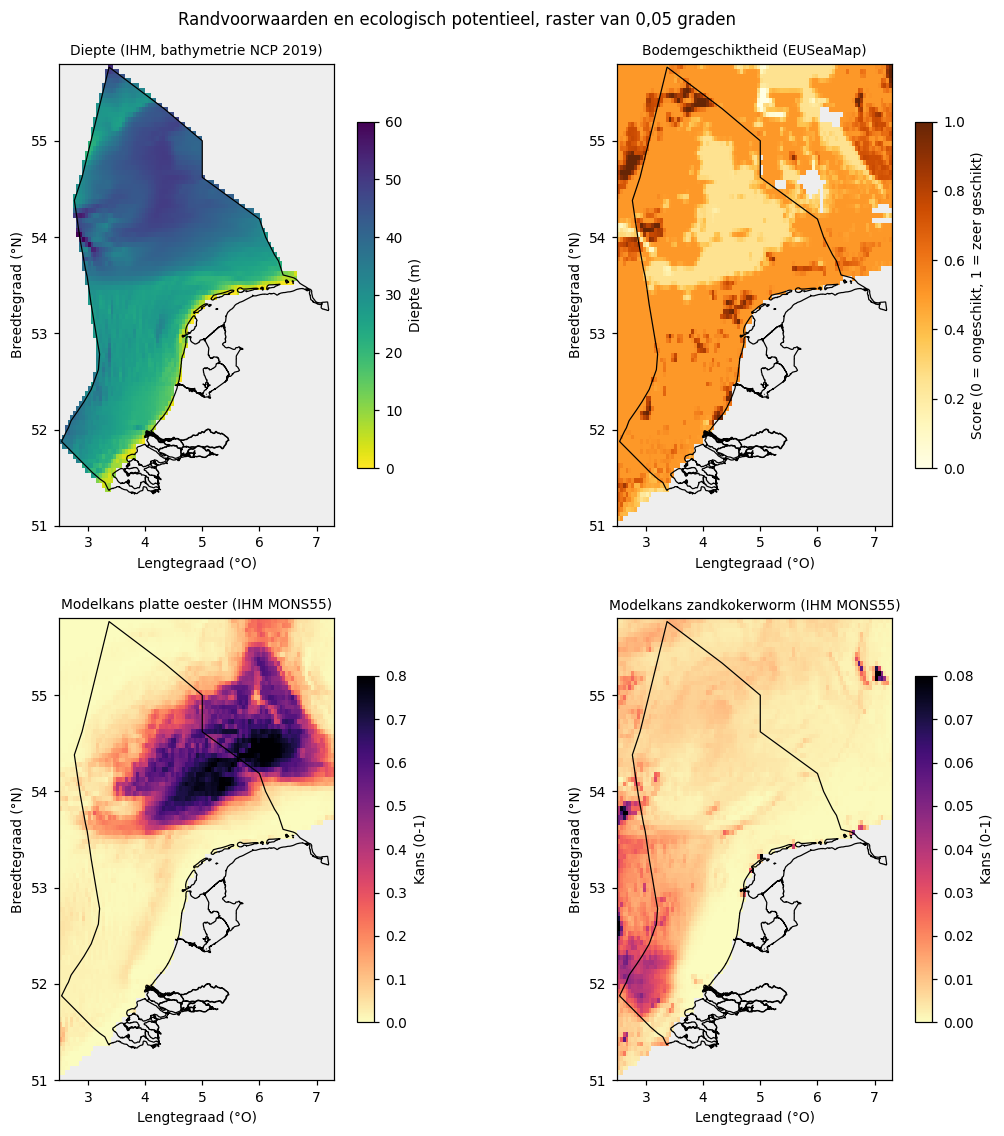

In [14]:
def grid_of(df, col):
    arr = np.full((NY, NX), np.nan)
    arr[df["iy"] - IY0, df["ix"] - IX0] = df[col].astype(float)
    return arr


ASPECT = 1 / np.cos(np.radians(53.4))


def base_map(ax, title):
    ax.set_facecolor("#eeeeee")
    ax.set_title(title, fontsize=9)
    ax.set_xlim(EXTENT[0], EXTENT[1])
    ax.set_ylim(EXTENT[2], EXTENT[3])
    ax.set_aspect(ASPECT)
    ax.set_xlabel("Lengtegraad (°O)")
    ax.set_ylabel("Breedtegraad (°N)")


def eez_outline(ax):
    eez.boundary.plot(ax=ax, color="black", linewidth=0.8)


def show(ax, arr, title, cmap="viridis", vmin=None, vmax=None, label=""):
    base_map(ax, title)
    im = ax.imshow(arr, origin="lower", extent=EXTENT, cmap=cmap, vmin=vmin, vmax=vmax, aspect=ASPECT, interpolation="nearest")
    eez_outline(ax)
    plt.colorbar(im, ax=ax, shrink=0.75, label=label)


fig, axes = plt.subplots(2, 2, figsize=(12, 12))
show(axes[0, 0], grid_of(cl, "depth_m"), "Diepte (IHM, bathymetrie NCP 2019)", "viridis_r", 0, 60, "Diepte (m)")
show(axes[0, 1], grid_of(cl, "substrate_score"), "Bodemgeschiktheid (EUSeaMap)", "YlOrBr", 0, 1, "Score (0 = ongeschikt, 1 = zeer geschikt)")
show(axes[1, 0], grid_of(cl, "p_ostrea"), "Modelkans platte oester (IHM MONS55)", "magma_r", 0, 0.8, "Kans (0-1)")
show(axes[1, 1], grid_of(cl, "p_sabellaria"), "Modelkans zandkokerworm (IHM MONS55)", "magma_r", 0, 0.08, "Kans (0-1)")
fig.suptitle("Randvoorwaarden en ecologisch potentieel, raster van 0,05 graden", y=0.92)
plt.show()

**Wat tonen de kaarten?** Diepte (linksboven) loopt van minder dan 10 m langs de kust tot ongeveer 45 tot 50 m in het noorden. De bodemgeschiktheid (rechtsboven) is hoog op grof en gemengd sediment en laag op slibrijk zand. De twee onderste kaarten tonen de modelkans voor de platte oester en de zandkokerworm.

**Interpretatie.**

- De modelkans voor de platte oester is hoog in het noordelijke deel van de EEZ (tot 0,83). Langs de kust is de kans laag.
- De modelkans voor de zandkokerworm en de paardenmossel is veel lager (hoogste waarde 0,10 en 0,05). Let op de andere schaal. Het notebook gebruikt daarom rangen in plaats van ruwe kansen.
- Het bodemtype is bijna overal *zand* (ongeveer 76% van het celoppervlak). Grof of gemengd sediment is zeldzaam. De bodemscore onderscheidt de cellen dus weinig. De rangschikking hangt daardoor vooral af van de modelkansen en de diepte.
- De modelkaarten zijn voorspellingen uit waarnemingen. Ze tonen geen vastgestelde aanwezigheid.

## 7.2 Drukfactoren, bescherming en bewijs van aanwezigheid

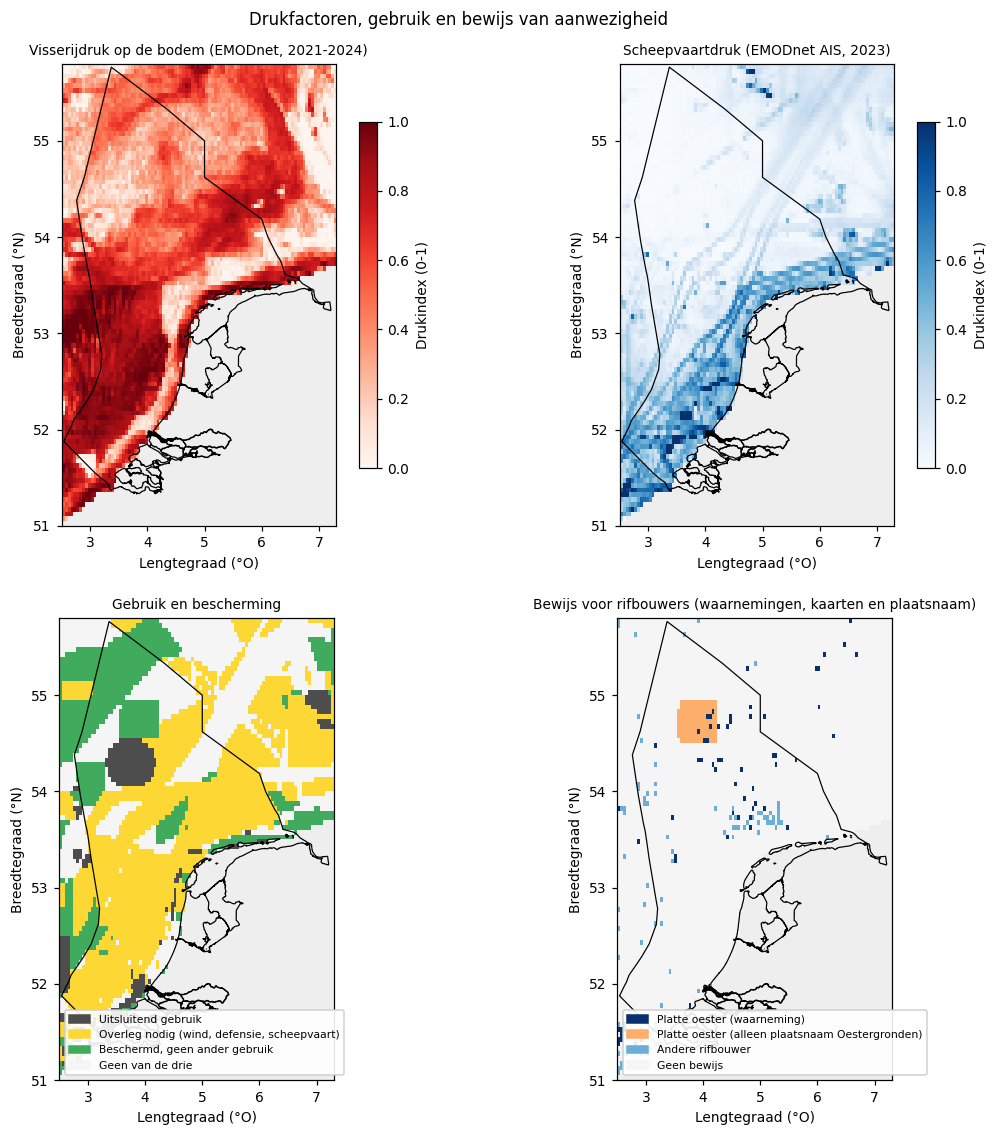

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
show(axes[0, 0], grid_of(cl, "fish_idx"), "Visserijdruk op de bodem (EMODnet, 2021-2024)", "Reds", 0, 1, "Drukindex (0-1)")
show(axes[0, 1], grid_of(cl, "ship_idx"), "Scheepvaartdruk (EMODnet AIS, 2023)", "Blues", 0, 1, "Drukindex (0-1)")

use_code = np.zeros(len(cl))
use_code[cl["negotiate"]] = 2
use_code[cl["blocked"]] = 1
use_code[cl["protected"] & ~cl["blocked"] & ~cl["negotiate"]] = 3
use_cmap = ListedColormap(["#f5f5f5", "#4d4d4d", "#fdd835", "#41ab5d"])
base_map(axes[1, 0], "Gebruik en bescherming")
axes[1, 0].imshow(grid_of(cl.assign(c=use_code), "c"), origin="lower", extent=EXTENT, cmap=use_cmap, vmin=0, vmax=3, aspect=ASPECT, interpolation="nearest")
eez_outline(axes[1, 0])
axes[1, 0].legend(handles=[Patch(color="#4d4d4d", label="Uitsluitend gebruik"), Patch(color="#fdd835", label="Overleg nodig (wind, defensie, scheepvaart)"),
                           Patch(color="#41ab5d", label="Beschermd, geen ander gebruik"), Patch(color="#f5f5f5", label="Geen van de drie")],
                  loc="lower left", fontsize=7, framealpha=0.9)

ev_code = np.zeros(len(cl))
ev_code[cl["ev_other_reef"]] = 1
ev_code[cl["ev_ostrea_name"]] = 2
ev_code[cl["ev_ostrea_obs"]] = 3
ev_cmap = ListedColormap(["#f5f5f5", "#6baed6", "#fdae6b", "#08306b"])
base_map(axes[1, 1], "Bewijs voor rifbouwers (waarnemingen, kaarten en plaatsnaam)")
axes[1, 1].imshow(grid_of(cl.assign(c=ev_code), "c"), origin="lower", extent=EXTENT, cmap=ev_cmap, vmin=0, vmax=3, aspect=ASPECT, interpolation="nearest")
eez_outline(axes[1, 1])
axes[1, 1].legend(handles=[Patch(color="#08306b", label="Platte oester (waarneming)"), Patch(color="#fdae6b", label="Platte oester (alleen plaatsnaam Oestergronden)"),
                           Patch(color="#6baed6", label="Andere rifbouwer"), Patch(color="#f5f5f5", label="Geen bewijs")],
                  loc="lower left", fontsize=7, framealpha=0.9)
fig.suptitle("Drukfactoren, gebruik en bewijs van aanwezigheid", y=0.92)
plt.show()

**Wat tonen de kaarten?** De bovenste kaarten tonen de visserijdruk en de scheepvaartdruk. Linksonder staan de gebieden met uitsluitend gebruik, de gebieden waar overleg nodig is en de beschermde gebieden. Rechtsonder staan de cellen met een waarneming of kaart van een rifbouwer.

**Interpretatie.**

- Bodemvisserij raakt bijna de hele EEZ. De gemiddelde drukindex is 0,56. Enkele gebieden in het noordoosten en een aantal beschermde gebieden hebben een lagere druk.
- Scheepvaart is geconcentreerd in routes. De druk is hoog bij de aanloop naar IJmuiden en in het zuidwesten. Elders is de druk laag.
- Veel cellen vragen overleg: 1.879 van 3.202 cellen liggen in een windpark, defensiegebied of scheepvaartzone. Slechts 251 cellen vallen af door uitsluitend gebruik. 1.200 cellen hebben geen van beide.
- Bewijs voor rifbouwers is schaars. Er zijn 41 cellen met een waarneming van de platte oester en 55 met een andere rifbouwer. In 90% van de cellen is geen MWTL-benthosmonster genomen. Een lege cel in de bewijskaart betekent dus *geen gegevens*, niet *afwezig*.
- Het oranje vlak (Oestergronden) is geen waarneming. Het toont alleen de plaatsnaam.

## 7.3 Indeling en zones

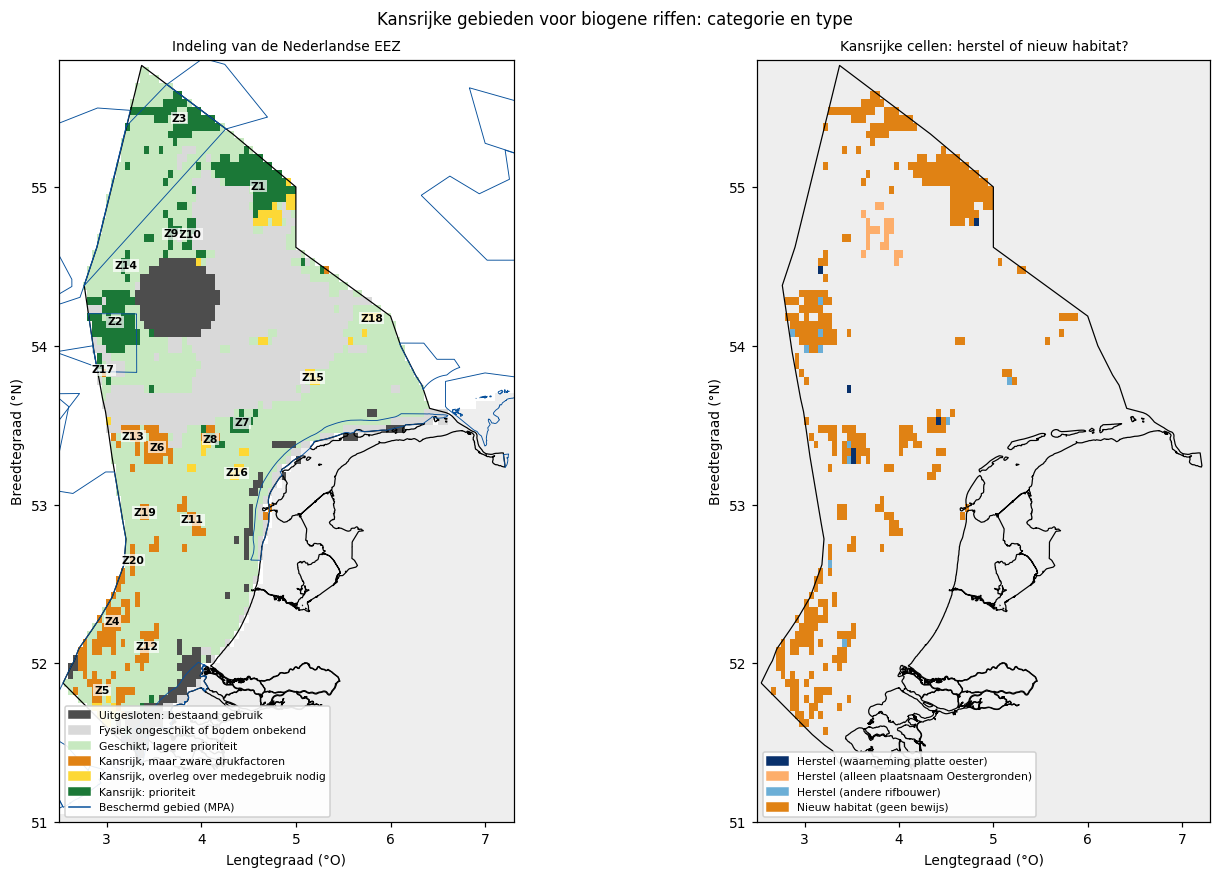

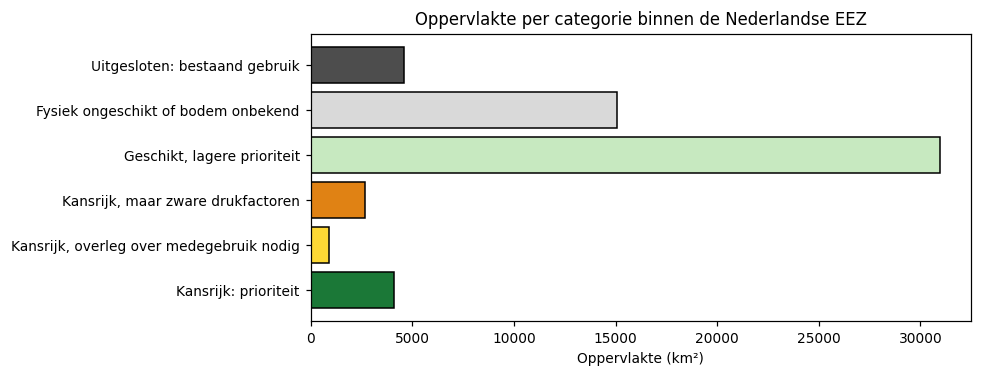

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 9))
cat_cmap = ListedColormap(CAT_COLORS)
base_map(axes[0], "Indeling van de Nederlandse EEZ")
axes[0].imshow(np.where(np.isnan(grid_of(cl, "category")), np.nan, grid_of(cl, "category")), origin="lower", extent=EXTENT,
               cmap=cat_cmap, vmin=0, vmax=6, aspect=ASPECT, interpolation="nearest")
eez_outline(axes[0])
mpa.boundary.plot(ax=axes[0], color="#08519c", linewidth=0.6)
for name, g in cl[cl["zone"].notna()].groupby("zone"):
    axes[0].text(g["lon"].mean(), g["lat"].mean(), name, fontsize=7, ha="center", va="center", fontweight="bold",
                 bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.7))
axes[0].legend(handles=[Patch(color=CAT_COLORS[i], label=CATEGORIES[i]) for i in range(1, 7)] +
               [plt.Line2D([0], [0], color="#08519c", lw=1, label="Beschermd gebied (MPA)")], loc="lower left", fontsize=7, framealpha=0.9)

type_code = np.full(len(cl), np.nan)
promising_mask = cl["category"].isin([4, 5, 6])
for code, label in enumerate(["Nieuw habitat", "Herstel (andere rifbouwer)", "Herstel (platte oester, alleen plaatsnaam)", "Herstel (platte oester, waarneming)"]):
    type_code[promising_mask & (cl["evidence_type"] == label)] = code
base_map(axes[1], "Kansrijke cellen: herstel of nieuw habitat?")
axes[1].imshow(grid_of(cl.assign(c=type_code), "c"), origin="lower", extent=EXTENT,
               cmap=ListedColormap(["#e08214", "#6baed6", "#fdae6b", "#08306b"]), vmin=0, vmax=3, aspect=ASPECT, interpolation="nearest")
eez_outline(axes[1])
axes[1].legend(handles=[Patch(color="#08306b", label="Herstel (waarneming platte oester)"), Patch(color="#fdae6b", label="Herstel (alleen plaatsnaam Oestergronden)"),
                        Patch(color="#6baed6", label="Herstel (andere rifbouwer)"), Patch(color="#e08214", label="Nieuw habitat (geen bewijs)")],
               loc="lower left", fontsize=7, framealpha=0.9)
fig.suptitle("Kansrijke gebieden voor biogene riffen: categorie en type", y=0.93)
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.5))
bar = summary.reset_index().rename(columns={"index": "Categorie"})
ax.barh(bar["Categorie"], bar["Oppervlakte_km2"], color=[CAT_COLORS[k] for k in summary_codes], edgecolor="black")
ax.set_xlabel("Oppervlakte (km²)")
ax.set_title("Oppervlakte per categorie binnen de Nederlandse EEZ")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Wat tonen de kaarten?** Links staat de indeling in categorieën, met de zones (Z1, Z2, enzovoort) en de beschermde gebieden. Rechts staat voor de kansrijke cellen of het gaat om herstel (bewijs voor de soort) of nieuw habitat.

**Interpretatie en voorbehoud.**

- Van de 3.202 cellen zijn 424 kansrijk (7.692 km², 13% van de EEZ). Daarvan zijn 232 cellen *prioriteit*, 50 cellen vragen overleg en 142 cellen hebben zware drukfactoren.
- De zones met veel prioriteitscellen liggen in het noorden en noordwesten (Z1, Z3), bij de Klaverbank (Z2), de Oestergronden (Z9 en Z10) en het Friese Front (Z7). Zones in het zuiden (Z4, Z5, Z6, Z11, Z12) zijn kansrijk volgens de modelkaart, maar de visserij- en scheepvaartdruk is er hoog.
- Van de 424 kansrijke cellen heeft 91% (387 cellen) geen enkele aanwijzing voor eerdere aanwezigheid. Dat is **nieuw habitat** en geen herstel. Voor 37 cellen is er een aanwijzing: 6 cellen met een waarneming van de platte oester, 20 cellen met alleen de plaatsnaam Oestergronden en 11 cellen met een andere rifbouwer.
- De categorieën hangen af van de aannames in sectie 3.1. Een kansrijke cel is een plek om te onderzoeken en geen besluit.

## 7.4 Waarom is de natuurwaarde laag?

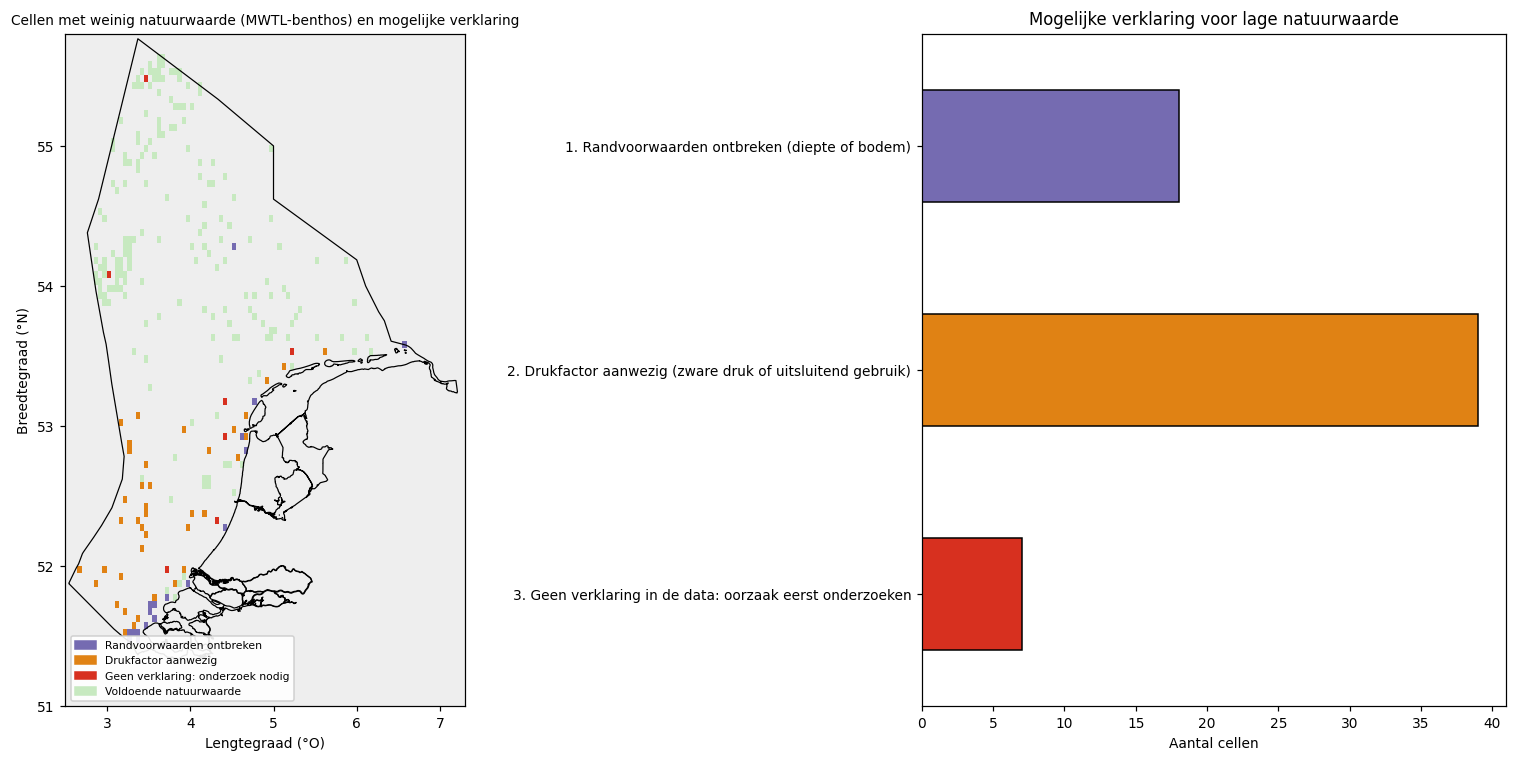

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1.3, 1]})
cause_code = np.full(len(cl), np.nan)
sel = cl["low_value"].fillna(False).astype(bool)
cause_code[sel & cl["cause"].str.startswith("1", na=False)] = 0
cause_code[sel & cl["cause"].str.startswith("2", na=False)] = 1
cause_code[sel & cl["cause"].str.startswith("3", na=False)] = 2
sampled_ok = cl["benthos_samples"].fillna(0) >= MIN_BENTHOS_SAMPLES
cause_code[~sel & sampled_ok & cl["low_value"].notna()] = 3
base_map(axes[0], "Cellen met weinig natuurwaarde (MWTL-benthos) en mogelijke verklaring")
axes[0].imshow(grid_of(cl.assign(c=cause_code), "c"), origin="lower", extent=EXTENT,
               cmap=ListedColormap(["#756bb1", "#e08214", "#d7301f", "#c7e9c0"]), vmin=0, vmax=3, aspect=ASPECT, interpolation="nearest")
eez_outline(axes[0])
axes[0].legend(handles=[Patch(color="#756bb1", label="Randvoorwaarden ontbreken"), Patch(color="#e08214", label="Drukfactor aanwezig"),
                        Patch(color="#d7301f", label="Geen verklaring: onderzoek nodig"), Patch(color="#c7e9c0", label="Voldoende natuurwaarde")],
               loc="lower left", fontsize=7, framealpha=0.9)
cause_table["Cellen"].plot.barh(ax=axes[1], color=["#756bb1", "#e08214", "#d7301f"][: len(cause_table)], edgecolor="black")
axes[1].set_xlabel("Aantal cellen")
axes[1].set_ylabel("")
axes[1].set_title("Mogelijke verklaring voor lage natuurwaarde")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

**Wat tonen de grafieken?** Links staan alleen de cellen met minimaal 3 monsters. Rood zijn cellen met weinig soorten waarvoor de data geen verklaring geven. Rechts staat het aantal cellen per mogelijke verklaring.

**Interpretatie.**

- Van de 249 cellen met minimaal 3 monsters hebben 64 cellen weinig soorten (hoogstens 17,7 taxa per monster).
- Bij 39 van die 64 cellen (61%) is een drukfactor aanwezig. Bij 18 cellen (28%) zijn diepte of bodem niet geschikt. Bij slechts 7 cellen (11%) geven de data geen verklaring.
- Soortenrijkdom en drukindex hangen negatief samen (Spearman -0,61; alleen visserij -0,49). Dit is geen bewijs voor oorzaak en gevolg. Diepte, bodem en afstand tot de kust spelen ook mee.
- Alleen de rode groep (7 cellen) is een goede kandidaat voor onderzoek naar de oorzaak. Voor de andere cellen is herstel pas zinvol als de drukfactor eerst afneemt of als herstel op een andere plek plaatsvindt.
- Van de 52 kansrijke cellen met monsters hebben er 7 (13%) weinig soorten. De overige 45 cellen hebben geen aanwijzing voor een rifbouwer in de monsters. Dat wijst op **nieuw habitat**.

# 8. Validatie en betrouwbaarheidscontroles

## 8.1 Dieptecontrole: twee bronnen

De dieptekaart uit `mon_morphology_bathymetry_ncp_2019` (Nederlands Continentaal Plat) is de basis. De controle vergelijkt die met de aparte dieptelaag `prj_nzb_depth`. Die laag heeft niet overal waarden.

Cellen met beide dieptes: 2458 van 3202 cellen in de EEZ
Correlatie (Pearson): 0.984
Mediaan van het verschil NZB min NCP: 0.2 m | gemiddeld absoluut verschil: 0.9 m
Binnen 5 m: 99% | binnen 10 m: 99%
Cellen in het dieptebereik (10, 50): NCP 2349 | NZB 2358 | beide 2340


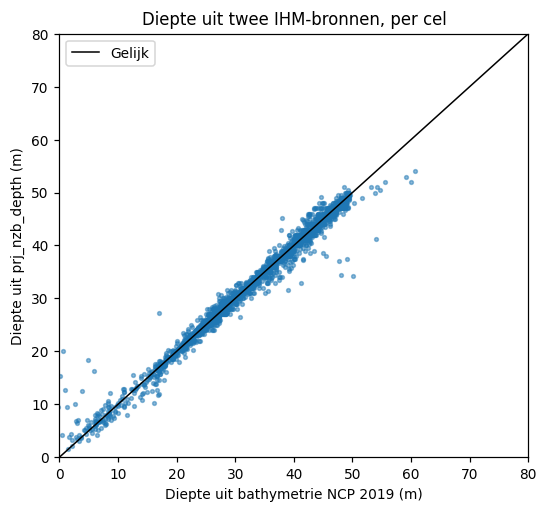

In [18]:
both = cl[cl["in_nl"] & cl["depth_m"].notna() & cl["depth_nzb_m"].notna()]
diff = both["depth_nzb_m"] - both["depth_m"]
print(f"Cellen met beide dieptes: {len(both)} van {int(cl['in_nl'].sum())} cellen in de EEZ")
print(f"Correlatie (Pearson): {both['depth_m'].corr(both['depth_nzb_m']):.3f}")
print(f"Mediaan van het verschil NZB min NCP: {diff.median():.1f} m | gemiddeld absoluut verschil: {diff.abs().mean():.1f} m")
print(f"Binnen 5 m: {(diff.abs() <= 5).mean():.0%} | binnen 10 m: {(diff.abs() <= 10).mean():.0%}")
in_a = both["depth_m"].between(*DEPTH_RANGE_M)
in_b = both["depth_nzb_m"].between(*DEPTH_RANGE_M)
print(f"Cellen in het dieptebereik {DEPTH_RANGE_M}: NCP {in_a.sum()} | NZB {in_b.sum()} | beide {(in_a & in_b).sum()}")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(both["depth_m"], both["depth_nzb_m"], s=6, alpha=0.5)
lim = [0, 80]
ax.plot(lim, lim, color="black", lw=1, label="Gelijk")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("Diepte uit bathymetrie NCP 2019 (m)")
ax.set_ylabel("Diepte uit prj_nzb_depth (m)")
ax.set_title("Diepte uit twee IHM-bronnen, per cel")
ax.legend()
plt.show()

## 8.2 Bodemtype uit EUSeaMap tegenover MWTL-slibfractie

Het bodemtype is uit een kaartafbeelding afgeleid. De controle toetst of cellen met slibrijke klassen ook in de onafhankelijke MWTL-metingen meer slib (fractie kleiner dan 63 µm) tonen.

In [19]:
m = cl[cl["in_nl"] & cl["mud_n"].notna()]
tab = m.groupby("dominant_substrate").agg(Cellen=("ix", "size"), Slib_procent=("mud_pct", "mean"), Slib_mediaan=("mud_pct", "median"))
display(tab.round(1))
rho = m["mud_pct"].corr(1 - m["substrate_score"], method="spearman")
print(f"Cellen met MWTL-slibfractie: {len(m)} | Spearman tussen slibfractie en (1 - bodemscore): {rho:.2f}")

,Cellen,Slib_procent,Slib_mediaan
dominant_substrate,,,
Coarse substrate,2,7.000,7.000
Muddy sand,4,28.600,31.200
Sand,44,14.200,12.700
Seabed,4,22.800,23.000


Cellen met MWTL-slibfractie: 54 | Spearman tussen slibfractie en (1 - bodemscore): 0.22


## 8.3 Visserijdruk uit twee bronnen

De drukindex voor visserij (EMODnet, VMS) is vergeleken met de IHM-laag `prj_dt_fish_yield_2008_2018` (eenheid niet beschreven). Een positieve samenhang geeft vertrouwen dat beide lagen dezelfde gebieden als intensief aanwijzen. Het geeft geen bewijs voor oorzaak.

In [20]:
v = cl[cl["in_nl"] & cl["dt_yield"].notna()]
print(f"Cellen met beide bronnen: {len(v)} van {int(cl['in_nl'].sum())}")
print(f"Spearman tussen visserijindex EMODnet en DT-opbrengst: {v['fish_idx'].corr(v['dt_yield'], method='spearman'):.2f}")

Cellen met beide bronnen: 3202 van 3202
Spearman tussen visserijindex EMODnet en DT-opbrengst: 0.68


## 8.4 Volledigheid, dubbele cellen en monitoringdekking

In [21]:
nl = cl[cl["in_nl"]]
checks = pd.DataFrame({
    "Cellen zonder waarde": {c: int(nl[c].isna().sum()) for c in ["depth_m", "substrate_score", "p_ostrea", "vessel_density", "benthos_samples", "mud_pct", "dt_yield"]}
})
checks["Aandeel"] = checks["Cellen zonder waarde"] / len(nl)
display(checks.round(3))
print("Dubbele cellen in het raster:", int(cl.duplicated(["ix", "iy"]).sum()))
top = nl[nl["category"].isin([4, 5, 6])]
print(f"Kansrijke cellen met minimaal 1 benthosmonster: {(top['benthos_samples'].fillna(0) >= 1).mean():.0%} | met minimaal 3 monsters: {(top['benthos_samples'].fillna(0) >= 3).mean():.0%}")
print(f"Kansrijke cellen met een WOT-station: {(top['wot_stations'].fillna(0) >= 1).mean():.0%}")
print(f"Kansrijke cellen met minimaal 1 MONS55-waarneming van de rifbouwers: {((top[['n_obs_ostrea', 'n_obs_sabellaria', 'n_obs_modiolus']].fillna(0).sum(axis=1)) >= 1).mean():.0%}")

,Cellen zonder waarde,Aandeel
depth_m,0,0.000
substrate_score,12,0.004
p_ostrea,0,0.000
vessel_density,0,0.000
benthos_samples,2868,0.896
mud_pct,3148,0.983
dt_yield,0,0.000


Dubbele cellen in het raster: 0
Kansrijke cellen met minimaal 1 benthosmonster: 15% | met minimaal 3 monsters: 12%
Kansrijke cellen met een WOT-station: 1%
Kansrijke cellen met minimaal 1 MONS55-waarneming van de rifbouwers: 58%


## 8.5 Gevoeligheid voor de aannames

De analist koos de grenzen en gewichten. De volgende tabel toont hoeveel de kansrijke selectie (categorie 4, 5 en 6) verandert als een keuze verandert. De **overlap** is het aandeel gedeelde cellen (Jaccard: gedeelde cellen gedeeld door alle cellen in een van beide selecties). Een hoge overlap betekent een robuuste keuze.

In [22]:
scenarios = {
    "Basis": {},
    "Diepte 5-60 m": dict(depth_range=(5, 60)),
    "Diepte 15-40 m": dict(depth_range=(15, 40)),
    "Alleen platte oester": dict(species_weights={"p_ostrea": 1.0}),
    "Gelijke gewichten voor de 3 soorten": dict(species_weights={"p_ostrea": 1, "p_sabellaria": 1, "p_modiolus": 1}),
    "Strengere bodemeis (alleen grof en gemengd)": dict(min_substrate=0.6),
    "Kansrijk = top 10%": dict(top_fraction=0.10),
    "Kansrijk = top 30%": dict(top_fraction=0.30),
}
base_sel = classify(cells, **scenarios["Basis"])
base_set = set(map(tuple, base_sel.loc[base_sel["category"].isin([4, 5, 6]), ["ix", "iy"]].to_numpy()))
base_prio = set(map(tuple, base_sel.loc[base_sel["category"] == 6, ["ix", "iy"]].to_numpy()))
rows = []
for name, kw in scenarios.items():
    s = classify(cells, **kw)
    sel_set = set(map(tuple, s.loc[s["category"].isin([4, 5, 6]), ["ix", "iy"]].to_numpy()))
    prio_set = set(map(tuple, s.loc[s["category"] == 6, ["ix", "iy"]].to_numpy()))
    rows.append({"Scenario": name, "Kansrijke cellen": len(sel_set), "Waarvan prioriteit": len(prio_set),
                 "Overlap kansrijk met basis": len(sel_set & base_set) / len(sel_set | base_set),
                 "Overlap prioriteit met basis": len(prio_set & base_prio) / max(len(prio_set | base_prio), 1)})
sens = pd.DataFrame(rows)
display(sens.round(2))
core = set.intersection(*[set(map(tuple, classify(cells, **kw).pipe(lambda s: s.loc[s["category"].isin([4, 5, 6]), ["ix", "iy"]]).to_numpy())) for kw in scenarios.values()])
print(f"Cellen die in alle {len(scenarios)} scenario's kansrijk blijven: {len(core)} van {len(base_set)} in het basisscenario")

# Per cel: in hoeveel scenario's is de cel kansrijk?
counts = pd.Series(0, index=pd.MultiIndex.from_frame(cells[["ix", "iy"]]))
for kw in scenarios.values():
    s = classify(cells, **kw)
    idx = pd.MultiIndex.from_frame(s.loc[s["category"].isin([4, 5, 6]), ["ix", "iy"]])
    counts.loc[idx] += 1
cl["scenarios_kansrijk"] = counts.reindex(pd.MultiIndex.from_frame(cl[["ix", "iy"]])).to_numpy()
cl["robuust"] = cl["scenarios_kansrijk"] >= 6
robust_zone = cl[cl["zone"].notna()].groupby("zone").agg(Cellen=("ix", "size"), Robuuste_cellen=("robuust", "sum"),
                                                        Gem_scenarios=("scenarios_kansrijk", "mean"))
robust_zone["Aandeel_robuust"] = robust_zone["Robuuste_cellen"] / robust_zone["Cellen"]
robust_zone = robust_zone.loc[sorted(robust_zone.index, key=lambda z: int(z[1:]))]
print(f"Robuuste cellen (kansrijk in minimaal 6 van {len(scenarios)} scenario's): {int(cl['robuust'].sum())}")
display(robust_zone.round(2))
zones = zones.merge(robust_zone[["Robuuste_cellen", "Aandeel_robuust"]].reset_index().rename(columns={"zone": "Zone"}), on="Zone", how="left")
zones.to_csv(os.path.join("output", "biogene_riffen_zones.csv"), index=False)
cl.loc[cl["in_nl"], ["ix", "iy", "lon", "lat", "depth_m", "dominant_substrate", "substrate_score", "p_ostrea", "p_sabellaria",
                     "p_modiolus", "eco_suit", "pressure_idx", "protected", "negotiate", "blocked", "evidence_type", "category",
                     "priority_score", "zone", "scenarios_kansrijk"]].to_csv(os.path.join("output", "biogene_riffen_cellen.csv"), index=False)

,Scenario,Kansrijke cellen,Waarvan prioriteit,Overlap kansrijk met basis,Overlap prioriteit met basis
0,Basis,424,232,1.000,1.000
1,Diepte 5-60 m,431,238,0.980,0.970
2,Diepte 15-40 m,335,111,0.550,0.390
3,Alleen platte oester,424,175,0.230,0.410
4,Gelijke gewichten voor de 3 soorten,424,186,0.600,0.680
5,Strengere bodemeis (alleen grof en gemengd),52,35,0.120,0.150
6,Kansrijk = top 10%,212,144,0.500,0.620
7,Kansrijk = top 30%,635,330,0.670,0.700


Cellen die in alle 8 scenario's kansrijk blijven: 26 van 424 in het basisscenario
Robuuste cellen (kansrijk in minimaal 6 van 8 scenario's): 178


,Cellen,Robuuste_cellen,Gem_scenarios,Aandeel_robuust
zone,,,,
Z1,85,29,4.920,0.340
Z2,58,42,6.280,0.720
Z3,45,33,5.840,0.730
Z4,34,18,6.030,0.530
Z5,33,5,5.150,0.150
Z6,23,6,5.090,0.260
Z7,11,10,6.640,0.910
Z8,12,4,5.080,0.330
Z9,8,0,4.380,0.000


## 8.6 Uitkomst van de controles

| Controle | Uitkomst | Beoordeling |
|---|---|---|
| Diepte uit twee IHM-bronnen (8.1) | Op 2.458 cellen met beide bronnen is de correlatie 0,98. 99% van de cellen verschilt minder dan 5 m. | Goed. De diepte is betrouwbaar. |
| Bodemtype tegenover MWTL-slibfractie (8.2) | Op 54 cellen met metingen is de slibfractie het hoogst bij *slibrijk zand* (29%), lager bij *zand* (14%) en het laagst bij *grof sediment* (7%, maar slechts 2 cellen). De rangcorrelatie is zwak (0,22). | Gedeeltelijk. De richting klopt. De kaart is een benadering en onderscheidt weinig. |
| Visserijdruk uit twee bronnen (8.3) | Rangcorrelatie 0,68 tussen de EMODnet-index en de IHM-laag `prj_dt_fish_yield_2008_2018`. | Redelijk. Beide lagen wijzen grotendeels dezelfde gebieden aan. Het zijn verschillende periodes en eenheden. |
| Dubbele of verloren cellen (8.4) | Geen dubbele cellen. Alle samenvoegingen behouden de 6.085 cellen van het raster. | Goed. |
| Monitoringdekking (8.4) | In 90% van de EEZ-cellen is geen MWTL-benthosmonster. Van de kansrijke cellen heeft 15% minimaal 1 monster en 12% minimaal 3. | **Niet goed.** Het ontbreken van gegevens beperkt alle conclusies over de huidige natuurwaarde. |
| Gevoeligheid voor aannames (8.5) | Slechts 26 van 424 kansrijke cellen blijven kansrijk in alle 8 scenario's. 178 cellen blijven kansrijk in minimaal 6 scenario's. De selectie verandert sterk bij *alleen platte oester* (overlap 23%) en bij een *strengere bodemeis* (12%). | Gedeeltelijk. Alleen een deel van de selectie is robuust. |
| Robuuste zones (8.5) | Hoog aandeel robuuste cellen: Friese Front Scholbox (Z15, 100%), Friese Front (Z7, 91%), Doggersbank (Z3, 73%), Klaverbank (Z2, 72%). Geen robuuste cellen in de Oestergronden (Z9 en Z10). | De Oestergronden liggen op 44 tot 45 m, vlak bij de gekozen dieptegrens van 50 m. Ze vallen weg bij een bereik van 15 tot 40 m. |

Geen controle is geslaagd door een aanname aan te passen. De zwakke punten staan hierboven.

# 9. Belangrijkste bevindingen en betekenis

## Antwoord op vraag a: welke gebieden zijn potentieel geschikt?

Van de 3.202 cellen (58.329 km²) in de Nederlandse EEZ zijn **424 cellen (7.692 km², 13%) kansrijk** voor biogene riffen. Deze cellen voldoen aan de eisen voor diepte en bodem, hebben een hoog ecologisch potentieel volgens de modelkaarten, en liggen niet in een uitsluitend gebruik. Het notebook ordent ze in 20 zones. De belangrijkste zijn:

| Zone | Gebied | Omvang | Wat valt op? | Type |
|---|---|---|---|---|
| Z2 | Klaverbank | 58 cellen, 1.045 km², 41 m | 86% beschermd, lage druk (0,13), 5 cellen met recent bewijs voor een andere rifbouwer, 72% robuust | Herstel (andere rifbouwer) |
| Z7 | Friese Front | 11 cellen, 201 km², 26 m | 64% beschermd, 91% robuust, 1 cel met een waarneming van de platte oester en 1 cel met een andere rifbouwer | Herstel |
| Z15 | Friese Front Scholbox | 4 cellen, 73 km² | Hoge modelkans voor de platte oester (0,34), 100% beschermd, overleg met medegebruik nodig, 1 cel met recent bewijs voor een andere rifbouwer | Herstel (andere rifbouwer) |
| Z9 en Z10 | Oestergronden | 15 cellen, 267 km², 44 tot 45 m | 100% beschermd, visserijbeperking, lage druk (0,10 en 0,17). Aanwijzing alleen via de plaatsnaam. Niet robuust bij een kleiner dieptebereik. | Herstel op basis van plaatsnaam |
| Z3 | Doggersbank | 45 cellen, 786 km², 32 m, grof sediment | 100% beschermd, druk 0,33, 73% robuust, geen aanwijzing voor rifbouwers in de cellen | Nieuw habitat |
| Z1 | Noorden (55,0°N, 4,6°O) | 85 cellen, 1.500 km², 44 m | Grootste zone. Lage druk (0,22), hoge modelkans (0,16), niet beschermd, geen bewijs | Nieuw habitat |
| Z4, Z5, Z6, Z11, Z12 | Zuidelijk deel | 113 cellen, ongeveer 2.100 km² samen | Hoge visserij- en scheepvaartdruk (0,57 tot 0,77), grotendeels niet beschermd (alleen Z4 deels, 35%) | Eerst druk aanpakken |

*Evidentie:* de kaarten, tabellen en getallen in sectie 6 en 7.

## Antwoord op vraag b: welke IHM-data waren bruikbaar?

- **Bruikbaar:** de MONS55-modelkaarten (potentieel), de MONS55-waarnemingen (aanwezigheid), de bathymetrie van het Nederlands Continentaal Plat (diepte), het MWTL-benthos en de WOT-schelpdieren (huidige aanwezigheid en natuurwaarde), en de MWTL-korrelgrootte en `prj_dt_fish_yield_2008_2018` (controles).
- **Ontbreekt in het IHM:** een bodemtypekaart, beschermde gebieden en gebruiksfuncties (scheepvaart, defensie, windparken, visserij-inspanning). Het notebook gebruikt hiervoor EMODnet en Marine Regions.
- **Dekking is beperkt:** slechts 10% van de cellen heeft een MWTL-benthosmonster en 1% van de kansrijke cellen heeft een WOT-station.

## Antwoord op vraag c: laag betekent niet automatisch kansrijk

- Van de 64 cellen met weinig soorten heeft 61% een drukfactor, 28% geschikte randvoorwaarden niet en 11% (7 cellen) geen verklaring in de data. Alleen de laatste groep vraagt eerst onderzoek naar de oorzaak.
- Soortenrijkdom en drukindex hangen negatief samen (-0,61). Dit bewijst geen oorzaak.
- **Herstel of nieuw habitat?** Van de 424 kansrijke cellen heeft 91% geen enkele aanwijzing voor eerdere aanwezigheid. Dat is **nieuw habitat**. Voor 37 cellen is er een aanwijzing: 6 met een waarneming van de platte oester, 20 met alleen de plaatsnaam Oestergronden en 11 met een andere rifbouwer. De bronnen bevatten geen gedateerde kaarten van historische oesterbanken. Het notebook kan historische geschiktheid dus niet vaststellen.
- Alleen **herstel** vraagt dat de soort er van oudsher thuishoort. Voor de meeste zones is dat met deze data niet te zeggen.

## Wat betekent dit voor de praktijk?

- De Klaverbank, het Friese Front en de Oestergronden combineren een lage druk, bescherming en enige aanwijzing voor eerdere aanwezigheid. Ze zijn de beste kandidaten voor *vervolgonderzoek*.
- Grote gebieden zonder aanwijzingen (Z1 en de Doggersbank) passen bij *nieuw habitat*. Dat is een andere opgave dan herstel.
- In het zuiden is eerst een vermindering van bodemvisserij en scheepvaartdruk nodig.
- Een locatiekeuze vraagt veldonderzoek, aanvullende bronnen en afstemming met beheerders. Dit notebook doet daar geen uitspraak over.

## Wat blijft onzeker?

- Of de modelkaarten kloppen op de schaal van een locatie.
- Of een waarneming van aanwezigheid duidt op een vroeger rif.
- De invloed van de gekozen aannames op de rangschikking (sectie 8.5).

# 10. Beperkingen en vervolgstappen

## Beperkingen

- **Modellen, geen metingen.** De habitatgeschiktheid komt uit modellen. Het notebook kent hun nauwkeurigheid niet.
- **Bodemtype is een benadering.** Het bodemtype is uit een kaartafbeelding van EUSeaMap afgeleid. EUSeaMap is zelf een model. Bijna alle cellen zijn *zand*, waardoor de bodemscore weinig onderscheidt.
- **Weinig bewijs voor historische aanwezigheid.** De data van de platte oester hebben geen datum. De plaatsnaam *Oestergronden* is een zwakke aanwijzing.
- **Beperkte dekking van monsters.** Slechts 10% van de cellen heeft een benthosmonster.
- **Visserij en scheepvaart.** De visserijdata dekken alleen schepen langer dan 12 m met VMS. Cellen zonder gegevens zijn op 0 gezet. De AIS-data zijn van 2023.
- **Gebruiksfuncties.** De gebruiksfuncties komen uit het Programma Noordzee en EMODnet. Planstatus en vergunningen kunnen veranderd zijn.
- **Resolutie.** Een cel is ongeveer 3,5 bij 5,5 km. Dat is te grof voor een locatiekeuze op perceelniveau.
- **Geen oorzaak en gevolg.** Correlaties tonen geen oorzaak.
- **Ontbrekende factoren.** Stroming, golven, temperatuur, voedsel, larvenaanvoer en ziekten (zoals *Bonamia*) zijn niet meegenomen.
- **Gewichten en grenzen zijn keuzes.** De uitkomst hangt ervan af (sectie 8.5).
- **Externe diensten.** De externe diensten kunnen veranderen. De resultaten in de tekst komen uit de uitvoering van 19 oktober 2026.

## Mogelijke vervolgstappen

1. Voeg gedateerde kaarten of literatuur over historische oesterbanken en rifgebieden toe en toets de zones daaraan.
2. Voer veldonderzoek uit in de zones Klaverbank, Friese Front en Oestergronden. Meet bodem, soorten en ziekten.
3. Voeg stroming, golven en temperatuur toe. Het IHM bevat daarvoor lagen (`prj_nzb_max_wave_height`, `prj_nzb_min_temperature`, `prj_nzb_max_temperature`). Deze lagen zijn nu niet gebruikt omdat ze niet op het raster passen.
4. Controleer de bodemkaart met de polygonen van EUSeaMap en met nieuwe monsters.
5. Herhaal de analyse met een fijner raster in de beste zones.
6. Bespreek de zones met beheerders van Natura 2000, windparken en defensie.

## Uitvoering en validatie

Het notebook is op 19 oktober 2026 **volledig uitgevoerd** in de beoogde omgeving (Python met de `beacon-api` bibliotheek en internettoegang tot de IHM-server en de externe diensten). Alle codecellen zijn zonder fout doorlopen. De validatie is **gedeeltelijk geslaagd**: zie sectie 8.6. Het notebook is daarom een eerste, gedocumenteerde selectie en geen geheel gevalideerd advies.

Resultaten zijn ook opgeslagen als `output/biogene_riffen_cellen.csv` (indeling per cel) en `output/biogene_riffen_zones.csv` (zones).